# Camera 2701: does the picture itself carry congestion information? (v10a: v9 plus the second-rater workflow)
**Two experiments.** *Experiment A, classification* is the original brief: the softmax CNN-RNN that maps each frame to one of nine Google duration bands (notebook `…_v6_clean`). *Experiment B, image information* is the main one and is this notebook: does the picture carry congestion information beyond the time of day? It trains the regression and residual models (sections 1–8) and judges the picture directly with two tests that do not use Google's minutes as the standard: blind human ratings (section 9) and an image-swap test (section 10).

**Why direct tests.** Google's travel time covers about 7 km of road, including the approaches before the first immigration booth, while the camera sits between the Singapore and Malaysian booths and sees only the stretch between them. A model can read the picture well and still score poorly against Google.

**Test 1: blind human ratings (section 9).** About 150 test frames, spread evenly over low to high Google delay, are shown with no time, no Google minutes and no model output. A person rates each carriageway from 1 (free flow) to 5 (jammed). The models are scored against the ratings: rank correlation, the same after removing what the time-of-day baseline explains, and the chance that a heavy frame (rated 4–5) scores higher than a light one (rated 1–2), overall and for pairs with similar clock baselines. The pass criteria are constants in the scoring cell; **set them before you start rating.**

**Test 2: image-swap test (section 10).** Every test frame keeps its time features and baseline but receives the picture of a different day at the same weekend/hour. A model that reads the congestion in the picture gets worse; the no-image control must not change.

**What is new in v10: the second independent rater.** The conclusions from test 1 are provisional until a second person has rated the same frames without seeing the first rater's labels. Section 9 now has these steps:
1. *Rater 1* rates in the form (cell 9), as in v9.
2. The next cell builds `rater_kit_rater2.html`: one self-contained file with only the pictures, in a different order (no times, file names, Google minutes, model output or rater 1's labels). In Colab it is also downloaded. The second person opens it in any browser, rates, and clicks *Download my ratings*, which gives `kit_ratings_rater2.csv`.
3. Put that file in `/content` and run the import cell; it creates `labels_rater2.csv`.
4. The scoring cell then reports the agreement between the raters (rank correlation, weighted kappa) and scores against the average of both. The following cell scores the selected model against each rater separately and checks that the two carriageways were assigned to the right directions.

**How to read the two tests together**
- Test 1 passes and test 2 shows the model uses the picture: the picture does tell heavy from light, and the weak score against Google comes from a label that covers road the camera cannot see.
- Test 1 fails but test 2 shows the model uses the picture: the model reads something, but not congestion; consider training against the human ratings.
- Test 2 shows no use of the picture: the model is only reading the clock.
- If the two raters disagree strongly, or the direction check shows the carriageways swapped, fix that first; the SG→JB result is the most exposed to it.

**Which model the picture tests use.** Sections 7 and 8, the pass criteria in the scoring cell, the per-rater cell and the direction check all use `best_image`, the best model that has an image input, which cell 6 prints. The overall validation winner can be the no-image control (it was, by 0.03 min, in one run) and that must not be the model judged on its picture.

**Unchanged.** Sections 1–8 are the v8/v9 notebook (residual model with the no-image control). If `/content` still holds the saved models of an identical run (same frames, split, settings and seeds), cell 6 reuses them instead of training (`REUSE_CHECKPOINTS`).

**Before you run**
- Runtime → Change runtime type → **T4 GPU**. Cell 2 opens a Google sign-in (project `swiftborder`); read its output as before.
- Agree one sentence with the second rater on which lanes are "toward Johor" and "toward Singapore", and put it in `BRIEFING` in the kit cell before building the file. Download the label and kit files before the session ends (Colab clears `/content`).

## 1. Config and helpers

In [1]:
import concurrent.futures as cf
import copy, datetime, gc, math, os, random, re
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from zoneinfo import ZoneInfo

SGT = ZoneInfo("Asia/Singapore")

# --- the two sources -----------------------------------------------------------
GCP_PROJECT = "swiftborder"
BUCKET      = "sg-lta-traffic-cameras"
CAMERA_ID   = "2701"
BQ_TABLE    = "swiftborder.causeway.travel_times"
FRAMES_DIR  = "/content/frames_2701"
OUT_DIR     = "/content"                              # models and csv files are written here

# --- study window (Singapore time): 6 Sep 2026 02:00 to the end of 4 Oct 2026 -----
WINDOW_START = datetime.datetime(2026, 9, 6, 2, 0, 0)
WINDOW_END   = datetime.datetime(2026, 10, 4, 23, 59, 59)

# Timezone of the raw timestamps. If the inspect cell shows they are UTC, set ZoneInfo("UTC").
FILENAME_TZ    = SGT     # timestamp inside the image object names
BQ_DATETIME_TZ = SGT     # only used if the BigQuery time column is a DATETIME/string (no timezone)

# --- duration classes: 20, 30, ... 90, 100+ minutes -----------------------------------------
BAND_MINUTES = np.array([20, 30, 40, 50, 60, 70, 80, 90, 100], dtype=float)   # class centres; the last is "100+"
N_BANDS = len(BAND_MINUTES)
BAND_EDGES = (BAND_MINUTES[:-1] + BAND_MINUTES[1:]) / 2                       # 25, 35, ... 95
BAND_LABELS = ["<25"] + [f"{int(a)}-<{int(b)}" for a, b in zip(BAND_EDGES[:-1], BAND_EDGES[1:])] + ["95+"]
BAND_NAMES = [str(int(m)) for m in BAND_MINUTES[:-1]] + ["100+"]
CENTRES = BAND_MINUTES                                                        # softmax probabilities -> expected minutes

def minutes_to_band(m):
    """Class of a Google duration in minutes: the nearest centre (<25 -> 20 ... 95+ -> 100+). -1 = no label."""
    if m is None or pd.isna(m):
        return -1
    return int(np.digitize(float(m), BAND_EDGES))

# --- alignment, split, training settings -----------------------------------------------
ALIGN_MODE, ALIGN_TOL_MIN = "nearest", 5      # "nearest" reading within 5 min, or "mean" of readings within 5 min
TEST_FRAC, VAL_DAYS = 0.20, 3                 # last 20% of days = test; last VAL_DAYS of the rest pick the epoch
EPOCHS, BATCH = 12, 32
LR_BACKBONE, LR_HEAD, WEIGHT_DECAY = 3e-5, 3e-4, 1e-2
LABEL_SMOOTH, DROPOUT = 0.1, 0.5
EVALS_PER_EPOCH, PATIENCE = 2, 4              # validate twice an epoch; stop after 4 validations without a better val MAE
SEEDS = (0, 1, 2)                             # every variant is trained once per seed -> mean +/- sd

DIRS = (("SG->JB", "sg_jb_min", "sg_jb_band"), ("JB->SG", "jb_sg_min", "jb_sg_band"))

# --- image object names -> Singapore time -----------------------------------------------
TS_PATTERNS = [re.compile(r"(\d{4})(\d{2})(\d{2})[T_-]?(\d{2})(\d{2})(\d{2})"),
               re.compile(r"(\d{4})-(\d{2})-(\d{2})[T_ ](\d{2})[:.\-]?(\d{2})[:.\-]?(\d{2})")]

def parse_frame_ts(name):
    base = os.path.basename(name)
    for pat in TS_PATTERNS:
        m = pat.search(base)
        if m:
            try:
                t = datetime.datetime(*map(int, m.groups()))
            except ValueError:
                continue
            return t.replace(tzinfo=FILENAME_TZ).astimezone(SGT).replace(tzinfo=None)
    return None

# --- BigQuery table -> long frame [ts, direction, minutes] -------------------------------
SG_TOK = {"sg", "sgp", "singapore", "woodlands", "mandai"}
JB_TOK = {"jb", "jbcq", "johor", "my", "mys", "malaysia", "bangunan", "sultan", "ciq"}
NUMERIC = {"INTEGER", "INT64", "FLOAT", "FLOAT64", "NUMERIC", "BIGNUMERIC"}
DIR_NAME_PRIORITY = (r"^direction$", r"direction", r"route_id|route", r"leg|path|segment", r"label|name")
STATUS_OK = {"OK", "SUCCESS"}

def canon_direction(label):
    """'SG_JB' (Singapore -> Johor), 'JB_SG', or None. Whole words are matched; the side named first is the origin
    (SG_TO_MY, mandai_to_shell_jb -> SG_JB; MY_TO_SG, jb_to_woodlands -> JB_SG)."""
    s = str(label).lower()
    words = re.split(r"[^a-z0-9]+", s)
    first = lambda toks: next((i for i, w in enumerate(words) if w in toks), -1)
    sg, jb = first(SG_TOK), first(JB_TOK)
    if sg >= 0 and jb >= 0 and sg != jb:
        return "SG_JB" if sg < jb else "JB_SG"
    if re.search(r"northbound|to[_\- >]*(jb|johor|malaysia)|->\s*(jb|johor)", s):
        return "SG_JB"
    if re.search(r"southbound|to[_\- >]*(sg|singapore|woodlands)|->\s*(sg|singapore)", s):
        return "JB_SG"
    return None

def pick_dir_col(values):
    """values: {STRING column: its distinct values}. The column whose values name both directions; a column called
    'direction' beats 'route_id' beats 'route_name', and a column with fewer distinct values beats one with more."""
    rank = lambda n: next((i for i, p in enumerate(DIR_NAME_PRIORITY) if re.search(p, n, re.I)), len(DIR_NAME_PRIORITY))
    ok = [n for n, vs in values.items() if {canon_direction(v) for v in vs} >= {"SG_JB", "JB_SG"}]
    return min(ok, key=lambda n: (rank(n), len(values[n]))) if ok else None

def guess_google_columns(schema):
    """schema: [(column, bigquery_type)]. Returns the columns to use; override any of them in G_OVERRIDE."""
    ts = [n for n, t in schema if t in ("TIMESTAMP", "DATETIME")]
    ts_col = next((n for n in ts if re.search(r"time|ts|collect|fetch|query|record|creat|observ", n, re.I)),
                  ts[0] if ts else None)
    dur = [n for n, t in schema if t in NUMERIC and re.search(r"duration|travel|minute|second|min|sec", n, re.I)]
    best = lambda cols: next((n for n in cols if "traffic" in n.lower()), cols[0] if cols else None)
    status_col = next((n for n, t in schema if t == "STRING" and re.fullmatch(r"(.*_)?status", n, re.I)), None)
    rank = lambda n: next((i for i, p in enumerate(DIR_NAME_PRIORITY) if re.search(p, n, re.I)), None)
    dir_cands = sorted([n for n, t in schema if t == "STRING" and n != status_col and rank(n) is not None], key=rank)
    dir_col = dir_cands[0] if dir_cands else None
    od = [next((n for n, t in schema if t == "STRING" and re.search(p, n, re.I)), None)
          for p in ("origin|from", "destination|dest|to$")]
    wide = {}
    for n in dur:                                  # one duration column per direction, e.g. sg_to_jb_duration_s
        d = canon_direction(n)
        if d and (d not in wide or ("traffic" in n.lower() and "traffic" not in wide[d].lower())):
            wide[d] = n
    layout = "long" if dir_col else "wide" if wide else "od" if all(od) else None
    return dict(layout=layout, ts_col=ts_col, dir_col=dir_col, od_cols=od if all(od) else None,
                duration_col=best(dur), wide=wide, status_col=status_col, unit=None, direction_map=None)

def to_minutes(series, name, unit=None):
    s = pd.to_numeric(series, errors="coerce")
    if unit is None:
        n = name.lower()
        unit = "s" if re.search(r"sec|_s$|_secs$", n) else "min" if re.search(r"min", n) else ("s" if s.median() > 400 else "min")
    return s / 60.0 if unit == "s" else s

def normalize_google(df, cols):
    """Raw BigQuery rows -> long frame [ts (Singapore time), direction (SG_JB / JB_SG), minutes]."""
    if not cols.get("layout") or not cols.get("ts_col"):
        raise ValueError(f"Couldn't detect the table layout ({cols}). Set G_OVERRIDE with layout "
                         "('long' | 'wide' | 'od'), ts_col, duration_col and dir_col (or wide / od_cols).")
    sc = cols.get("status_col")
    if sc and sc in df:                                   # failed lookups must not become labels
        good = df[sc].astype(str).str.strip().str.upper().isin(STATUS_OK)
        if not good.any():
            print(f"status filter skipped: no value of '{sc}' looks like OK ({df[sc].unique()[:5].tolist()})")
        elif not good.all():
            print(f"status filter: dropped {int((~good).sum())} of {len(df)} rows where '{sc}' is not OK")
            df = df[good]
    ts = pd.to_datetime(df[cols["ts_col"]])
    if ts.dt.tz is None:
        ts = ts.dt.tz_localize(BQ_DATETIME_TZ)
    ts = ts.dt.tz_convert(SGT).dt.tz_localize(None)
    if cols["layout"] in ("long", "od"):
        raw = (df[cols["dir_col"]] if cols["layout"] == "long"
               else df[cols["od_cols"][0]].astype(str) + " -> " + df[cols["od_cols"][1]].astype(str))
        dmap = {v: canon_direction(v) for v in raw.dropna().unique()}
        dmap.update(cols.get("direction_map") or {})
        unknown = [v for v, d in dmap.items() if d is None and v not in (cols.get("direction_map") or {})]
        if unknown:
            raise ValueError(f"Can't tell which way these values go: {unknown[:8]}. Set "
                             "G_OVERRIDE['direction_map'] = {value: 'SG_JB' | 'JB_SG' | None} (None drops the rows).")
        out = pd.DataFrame(dict(ts=ts, direction=raw.map(dmap),
                                minutes=to_minutes(df[cols["duration_col"]], cols["duration_col"], cols.get("unit"))))
    else:
        out = pd.concat([pd.DataFrame(dict(ts=ts, direction=d, minutes=to_minutes(df[c], c, cols.get("unit"))))
                         for d, c in cols["wide"].items()], ignore_index=True)
    out = out.dropna(subset=["ts", "direction", "minutes"])
    out = out[out["minutes"] > 0]
    return out.groupby(["ts", "direction"], as_index=False)["minutes"].median().sort_values("ts").reset_index(drop=True)

# --- Google 5-min readings -> the 10-min frames ------------------------------------------
def align_labels(frames, g, direction, mode=ALIGN_MODE, tol_min=ALIGN_TOL_MIN):
    """For every frame, the Google reading for one direction: columns minutes, google_ts, offset_min (Google minus frame
    time, in minutes). NaN where no reading lies within tol_min. 'nearest' = closest reading; 'mean' = average of all."""
    gd = g[g["direction"] == direction].sort_values("ts")
    out = pd.DataFrame({"minutes": np.nan, "google_ts": pd.NaT, "offset_min": np.nan}, index=frames.index)
    if gd.empty:
        return out
    if mode == "nearest":
        left = frames[["ts"]].assign(i=frames.index).astype({"ts": "datetime64[ns]"}).sort_values("ts")
        right = gd.assign(google_ts=gd["ts"]).astype({"ts": "datetime64[ns]"})[["ts", "google_ts", "minutes"]]
        m = pd.merge_asof(left, right, on="ts", direction="nearest", tolerance=pd.Timedelta(minutes=tol_min)).set_index("i")
        out.loc[m.index, "minutes"] = m["minutes"]
        out.loc[m.index, "google_ts"] = m["google_ts"]
    elif mode == "mean":
        gts, mins = gd["ts"].to_numpy("datetime64[ns]"), gd["minutes"].to_numpy()
        tol = np.timedelta64(int(tol_min * 60e9), "ns")
        for i, t in zip(frames.index, frames["ts"].to_numpy("datetime64[ns]")):
            lo, hi = np.searchsorted(gts, t - tol, "left"), np.searchsorted(gts, t + tol, "right")
            if hi > lo:
                out.loc[i, "minutes"] = mins[lo:hi].mean()
                out.loc[i, "google_ts"] = pd.Timestamp(int(gts[lo:hi].astype("int64").mean()))
    else:
        raise ValueError(f"Unknown ALIGN_MODE={mode!r}. Use 'nearest' or 'mean'.")
    out["offset_min"] = (out["google_ts"] - frames["ts"]).dt.total_seconds() / 60.0
    return out

def split_by_days(df, test_frac=TEST_FRAC, val_days=VAL_DAYS):
    """Consecutive days: first (1 - test_frac) of the days train, the rest test; the last val_days of train pick the epoch."""
    days = sorted(df["ts"].dt.date.unique())
    n_test = max(1, round(test_frac * len(days)))
    train_days, test_days = days[:-n_test], days[-n_test:]
    val = train_days[-val_days:] if val_days and len(train_days) > val_days + 3 else []
    fit = [d for d in train_days if d not in val]
    pick = lambda ds: df[df["ts"].dt.date.isin(ds)]
    return pick(fit), pick(val), pick(test_days), (fit, val, test_days)


## 2. Connect and inspect both sources
Lists the frames in the window and shows the BigQuery schema, a few rows, and the detected columns. The direction column is chosen by checking its actual values, not just its name.

In [2]:
try:
    from google.colab import auth
    print("Requesting Google Authentication...")
    auth.authenticate_user()
    print("Authentication successful!")
except Exception as e:
    print(f"Authentication failed: {e}")
    print("Please ensure you allow the pop-up and grant the requested permissions, then try running this cell again.")

from google.cloud import bigquery, storage

gcs = storage.Client(project=GCP_PROJECT)
bq = bigquery.Client(project=GCP_PROJECT)

def list_frames():
    """Image objects for CAMERA_ID whose timestamp falls inside the window."""
    pad = datetime.timedelta(days=1)
    months, d = [], WINDOW_START - pad
    while d <= WINDOW_END + pad:
        months.append(d.strftime("%Y-%m")); d += datetime.timedelta(days=1)
    rows, raw = [], []
    for mo in sorted(set(months)):
        for b in gcs.list_blobs(BUCKET, prefix=f"camera_id={CAMERA_ID}/month={mo}/"):
            if not b.name.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            raw.append(b.name)
            t = parse_frame_ts(b.name)
            if t is not None and WINDOW_START <= t <= WINDOW_END:
                rows.append(dict(blob=b.name, ts=t))
    if not rows:
        raise RuntimeError(f"No frames in the window. Example object names: {raw[:5]}")
    return pd.DataFrame(rows).drop_duplicates("ts").sort_values("ts").reset_index(drop=True)

try:
    frames_all = list_frames()
    gap = frames_all["ts"].diff().dt.total_seconds().div(60)
    print(f"{len(frames_all)} frames, {frames_all['ts'].min()} -> {frames_all['ts'].max()} (Singapore time)")
    print(f"minutes between frames: median {gap.median():.1f}, max {gap.max():.0f} | frames per day (min/median/max):",
          frames_all.groupby(frames_all['ts'].dt.date).size().agg(['min', 'median', 'max']).tolist())
    print("example object:", frames_all["blob"].iloc[0])

    table = bq.get_table(BQ_TABLE)
    schema = [(f.name, f.field_type) for f in table.schema]
    print(f"\n{BQ_TABLE}: {table.num_rows} rows")
    print(pd.DataFrame(schema, columns=["column", "type"]).to_string(index=False))
    print(bq.query(f"SELECT * FROM `{BQ_TABLE}` LIMIT 5").to_dataframe().to_string())

    guess = guess_google_columns(schema)
    # Confirm the direction column against the data: the STRING column whose values name both directions.
    values = {n: bq.query(f"SELECT DISTINCT `{n}` AS v FROM `{BQ_TABLE}` WHERE `{n}` IS NOT NULL LIMIT 50").to_dataframe()["v"].tolist()
              for n, t in schema if t == "STRING"}
    chosen = pick_dir_col(values)
    if chosen:
        guess.update(layout="long", dir_col=chosen)
    print("\nauto-detected:", guess)
    print("direction values:", {v: canon_direction(v) for v in values.get(guess["dir_col"], [])})
    print("status values   :", values.get(guess["status_col"]))
except Exception as e:
    print(f"\nCould not complete source inspection due to authorization or client error: {e}")
    raise

# If a guess is wrong, override it here, e.g. G_OVERRIDE = {"duration_col": "duration_in_traffic_sec", "unit": "s"}
G_OVERRIDE = {}


Requesting Google Authentication...
Authentication successful!
4042 frames, 2026-09-06 02:05:50 -> 2026-10-04 23:55:48 (Singapore time)
minutes between frames: median 10.0, max 220 | frames per day (min/median/max): [100.0, 143.0, 144.0]
example object: camera_id=2701/month=2026-09/2701_20260906T020550.jpg

swiftborder.causeway.travel_times: 22546 rows
                 column      type
            observed_at TIMESTAMP
        observed_at_sgt  DATETIME
      observed_date_sgt      DATE
               route_id    STRING
             route_name    STRING
              direction    STRING
                 status    STRING
             origin_lat     FLOAT
             origin_lng     FLOAT
               dest_lat     FLOAT
               dest_lng     FLOAT
             distance_m   INTEGER
           duration_sec   INTEGER
duration_in_traffic_sec   INTEGER
       congestion_ratio     FLOAT
              speed_kmh     FLOAT
          error_message    STRING
                       observed_a

## 3. Download the frames and load the Google durations
Drops rows whose status is not OK and prints how many were removed.

In [3]:
from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True                # tolerate damaged or truncated frames

def download_frames(frames):
    os.makedirs(FRAMES_DIR, exist_ok=True)
    bucket = gcs.bucket(BUCKET)
    def one(row):
        path = os.path.join(FRAMES_DIR, f"{CAMERA_ID}_{row.ts:%Y%m%dT%H%M%S}.jpg")
        try:
            if not os.path.exists(path):
                bucket.blob(row.blob).download_to_filename(path + ".part")
                os.replace(path + ".part", path)
            return path
        except Exception as exc:
            print("  failed:", row.blob, exc)
            return None
    with cf.ThreadPoolExecutor(8) as ex:               # the storage client's connection pool holds 10
        paths = list(tqdm(ex.map(one, frames.itertuples()), total=len(frames)))
    out = frames.assign(path=paths).dropna(subset=["path"]).reset_index(drop=True)
    print(f"{len(out)} of {len(frames)} frames in {FRAMES_DIR}")
    return out

def load_google():
    cols = {**guess, **G_OVERRIDE}
    pad = datetime.timedelta(days=1)
    lo, hi = WINDOW_START - pad, WINDOW_END + pad
    ts_type = dict(schema)[cols["ts_col"]]
    if ts_type == "TIMESTAMP":
        utc = lambda t: t.replace(tzinfo=SGT).astimezone(datetime.timezone.utc)
        params = [bigquery.ScalarQueryParameter("lo", "TIMESTAMP", utc(lo)), bigquery.ScalarQueryParameter("hi", "TIMESTAMP", utc(hi))]
    elif ts_type == "DATETIME":
        loc = lambda t: t.replace(tzinfo=SGT).astimezone(BQ_DATETIME_TZ).replace(tzinfo=None)
        params = [bigquery.ScalarQueryParameter("lo", "DATETIME", loc(lo)), bigquery.ScalarQueryParameter("hi", "DATETIME", loc(hi))]
    else:
        params = None
    sql = f"SELECT * FROM `{BQ_TABLE}`" + (f" WHERE `{cols['ts_col']}` >= @lo AND `{cols['ts_col']}` < @hi" if params else "")
    raw = bq.query(sql, job_config=bigquery.QueryJobConfig(query_parameters=params or [])).to_dataframe()
    g = normalize_google(raw, cols)
    g = g[(g["ts"] >= lo) & (g["ts"] <= hi)]
    print(f"{len(g)} Google readings in the window:",
          g.groupby("direction")["minutes"].describe()[["count", "min", "50%", "max"]].round(1).to_dict("index"))
    return g

frames = download_frames(frames_all)
g = load_google()


  0%|          | 0/4042 [00:00<?, ?it/s]

4042 of 4042 frames in /content/frames_2701
17231 Google readings in the window: {'JB_SG': {'count': 8616.0, 'min': 12.6, '50%': 22.9, 'max': 69.9}, 'SG_JB': {'count': 8615.0, 'min': 10.0, '50%': 23.7, 'max': 67.0}}


## 4. Align, assign bands, split by dates
Each frame takes the Google reading around its timestamp. The split is by whole days (FIT → VAL → TEST). The band table shows the training frames per band; bands are only used for the confusion matrix and band accuracy.

In [4]:
from IPython.display import display

for name, mcol, bcol in DIRS:
    prefix = mcol[:-len("_min")]                                      # sg_jb / jb_sg
    a = align_labels(frames, g, prefix.upper())
    frames[mcol] = a["minutes"]
    frames[f"{prefix}_google_ts"] = a["google_ts"]
    frames[f"{prefix}_align_offset_min"] = a["offset_min"]
    frames[bcol] = frames[mcol].map(minutes_to_band)

# Keep frames that have a Google reading in both directions.
df = frames.dropna(subset=[m for _, m, _ in DIRS]).sort_values("ts").reset_index(drop=True)
print(f"Usable aligned images: {len(df):,} of {len(frames):,}")
for name, mcol, _ in DIRS:
    off = df[mcol[:-len("_min")] + "_align_offset_min"].abs()
    print(f"{name}: |offset| mean {off.mean():.2f} min, median {off.median():.2f}, max {off.max():.2f}")
print("\nSample alignment:")
display(df[["ts", "sg_jb_google_ts", "sg_jb_align_offset_min", "sg_jb_min", "jb_sg_google_ts", "jb_sg_align_offset_min", "jb_sg_min"]].head(10))

# Chronological split by whole days: FIT -> VAL (picks the epoch) -> TEST.
fit_df, val_df, test_df, (fit_days, val_days, test_days) = split_by_days(df)
span = lambda ds: f"{ds[0]} -> {ds[-1]} ({len(ds)} days)" if ds else "none"
print(f"\nFIT : {span(fit_days)}, {len(fit_df):,} images\nVAL : {span(val_days)}, {len(val_df):,} images"
      f"\nTEST: {span(test_days)}, {len(test_df):,} images")
assert fit_df["ts"].max() < val_df["ts"].min() < test_df["ts"].min() if len(val_df) else fit_df["ts"].max() < test_df["ts"].min()

# Class counts on the training days (the bands are only used for the confusion matrix and the band accuracy).
counts_by_dir = []
for name, mcol, bcol in DIRS:
    counts = np.bincount(fit_df.loc[fit_df[bcol] >= 0, bcol], minlength=N_BANDS)
    print(f"\n{name} training days: {fit_df[mcol].min():.0f} / {fit_df[mcol].median():.0f} / {fit_df[mcol].max():.0f} min (min / median / max)")
    display(pd.DataFrame({"band": BAND_LABELS, "minutes": BAND_NAMES, "count": counts, "percent": counts / counts.sum() * 100}).round(2))
    empty = [l for l, n in zip(BAND_LABELS, counts) if n == 0]
    if empty:
        print(f"WARNING: no training examples for bands {empty}; a band classifier could never predict them.")


Usable aligned images: 4,042 of 4,042
SG->JB: |offset| mean 0.70 min, median 0.69, max 3.96
JB->SG: |offset| mean 0.70 min, median 0.69, max 2.25

Sample alignment:


,ts,sg_jb_google_ts,sg_jb_align_offset_min,sg_jb_min,jb_sg_google_ts,jb_sg_align_offset_min,jb_sg_min
0,2026-09-06 02:05:50,2026-09-06 02:05:00.834,-0.819433,13.716667,2026-09-06 02:05:00.834,-0.819433,18.350000
1,2026-09-06 02:15:51,2026-09-06 02:15:04.389,-0.776850,12.666667,2026-09-06 02:15:04.389,-0.776850,17.416667
2,2026-09-06 02:25:31,2026-09-06 02:25:04.264,-0.445600,12.066667,2026-09-06 02:25:04.264,-0.445600,17.900000
3,2026-09-06 02:35:31,2026-09-06 02:35:04.127,-0.447883,12.283333,2026-09-06 02:35:04.127,-0.447883,17.050000
4,2026-09-06 02:45:52,2026-09-06 02:45:03.898,-0.801700,11.750000,2026-09-06 02:45:03.898,-0.801700,16.783333
5,2026-09-06 02:55:52,2026-09-06 02:55:04.162,-0.797300,11.650000,2026-09-06 02:55:04.162,-0.797300,16.516667
6,2026-09-06 03:05:32,2026-09-06 03:05:03.599,-0.473350,11.583333,2026-09-06 03:05:03.599,-0.473350,16.916667
7,2026-09-06 03:15:53,2026-09-06 03:15:04.224,-0.812933,11.950000,2026-09-06 03:15:04.224,-0.812933,17.216667
8,2026-09-06 03:25:33,2026-09-06 03:25:03.593,-0.490117,11.616667,2026-09-06 03:25:03.593,-0.490117,17.783333
9,2026-09-06 03:35:34,2026-09-06 03:35:03.969,-0.500517,11.550000,2026-09-06 03:35:03.969,-0.500517,18.250000



FIT : 2026-09-06 -> 2026-09-25 (20 days), 2,770 images
VAL : 2026-09-26 -> 2026-09-28 (3 days), 431 images
TEST: 2026-09-29 -> 2026-10-04 (6 days), 841 images

SG->JB training days: 11 / 23 / 59 min (min / median / max)


,band,minutes,count,percent
0,<25,20,1516,54.73
1,25-<35,30,670,24.19
2,35-<45,40,431,15.56
3,45-<55,50,137,4.95
4,55-<65,60,16,0.58
5,65-<75,70,0,0.00
6,75-<85,80,0,0.00
7,85-<95,90,0,0.00
8,95+,100+,0,0.00



JB->SG training days: 13 / 22 / 70 min (min / median / max)


,band,minutes,count,percent
0,<25,20,1662,60.00
1,25-<35,30,556,20.07
2,35-<45,40,320,11.55
3,45-<55,50,173,6.25
4,55-<65,60,54,1.95
5,65-<75,70,5,0.18
6,75-<85,80,0,0.00
7,85-<95,90,0,0.00
8,95+,100+,0,0.00


## 5. Model, residual target, training, evaluation
The network is the v7/v8 one (CNN → BiGRU → one head per direction) with optional time features and an optional image branch. `residual` adds the time-of-day baseline to the output; `loo_tod_minutes` builds the leave-one-day-out baseline for the training frames. `make_model` builds an untrained network so saved models can be reloaded.

In [5]:
import torch.nn as nn, torch.nn.functional as F
from PIL import Image, ImageDraw, ImageOps
from torchvision import models

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.benchmark = True

ROAD_CROP = (0.34, 0.27, 1.00, 1.00)                  # left, top, right, bottom as fractions: just the causeway
CORRIDOR = [(0.340, 0.865), (1.000, 0.2753), (1.000, 0.3935), (0.386, 1.000), (0.340, 1.000)]   # 2026 road polygon
MEAN_RGB = (124, 116, 104)

def load_frame(path, crop=None, mask=False, equalize=False, grayscale=False, size=(288, 448)):
    """One frame -> uint8 (H, W, 3): crop, (equalise luminance), (grey out everything off the road), (grayscale), resize.
    Grayscale is repeated into 3 identical channels because the pretrained backbones expect RGB."""
    img = Image.open(path).convert("RGB")
    W0, H0 = img.size
    l, t, r, b = crop or (0, 0, 1, 1)                 # crop and CORRIDOR are fractions of the full frame
    img = img.crop((int(l * W0), int(t * H0), int(r * W0), int(b * H0)))
    W, H = img.size
    if equalize:
        y, cb, cr = img.convert("YCbCr").split()
        img = Image.merge("YCbCr", (ImageOps.equalize(y), cb, cr)).convert("RGB")
    if mask:
        m = Image.new("L", img.size, 0)
        ImageDraw.Draw(m).polygon([((x - l) / (r - l) * W, (y - t) / (b - t) * H) for x, y in CORRIDOR], fill=255)
        img = Image.composite(img, Image.new("RGB", img.size, MEAN_RGB), m)
    if grayscale:
        gray = img.convert("L")
        img = Image.merge("RGB", (gray, gray, gray))
    return np.asarray(img.resize((size[1], size[0]), Image.BILINEAR), dtype=np.uint8)

def build_cache(paths, cfg):
    """All frames of one variant as a uint8 tensor (N, H, W, 3)."""
    fn = lambda p: load_frame(p, cfg["crop"], cfg["mask"], cfg["equalize"], cfg["grayscale"], cfg["size"])
    X = np.empty((len(paths), *cfg["size"], 3), np.uint8)
    with cf.ThreadPoolExecutor(8) as ex:
        for i, arr in enumerate(tqdm(ex.map(fn, paths), total=len(paths), desc="Loading images")):
            X[i] = arr
    return torch.from_numpy(X)

# Sanity check of the grayscale filter on the first frame.
_g = load_frame(frames.iloc[0]["path"], crop=ROAD_CROP, grayscale=True)
assert np.array_equal(_g[..., 0], _g[..., 1]) and np.array_equal(_g[..., 1], _g[..., 2]), "grayscale: R, G, B differ"

def make_backbone(name):
    if name == "resnet18":
        return nn.Sequential(*list(models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1).children())[:-2])
    if name == "efficientnet_b0":
        return models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1).features
    raise ValueError(name)

# --- what the network is trained to output -------------------------------------------------------------------------
#   regression  the Google minutes directly (v7)
#   residual    the Google minutes minus the time-of-day baseline for that frame: prediction = baseline + network output.
#               The head starts at zero, so training starts exactly at the time-of-day baseline and the image can only help
#               by explaining what the hour and weekday do not.
LOSSES = ("regression", "residual")
REG_SCALE = 10.0                                      # the head works in tens of minutes
TIME_DIM = 11                                         # sin/cos of the hour (2 harmonics) + weekday one-hot

def time_features(ts):
    """Hour of day (2 harmonics) and weekday one-hot, one row per timestamp."""
    h = (ts.dt.hour + ts.dt.minute / 60.0).values
    cols = [np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24), np.sin(4 * np.pi * h / 24), np.cos(4 * np.pi * h / 24)]
    cols += [(ts.dt.dayofweek.values == k).astype(float) for k in range(7)]
    return torch.tensor(np.stack(cols, 1), dtype=torch.float32)

class CNNRNN(nn.Module):
    """CNN feature map -> BiGRU scanning the image left to right (columns follow distance along the diagonal
    causeway; height stays inside each step so the two carriageways stay separable) -> one head per direction.
    use_time: the hour / weekday features are also given to the head (through a small layer).
    use_image=False drops the CNN and the GRU entirely (a time-features-only control).
    freeze = number of leading backbone modules to keep fixed (0 = train everything)."""
    def __init__(self, backbone, size, loss="regression", hidden=128, freeze=0, init_minutes=(25.0, 25.0), use_time=False, use_image=True):
        super().__init__()
        self.freeze, self.use_time, self.use_image = freeze, use_time, use_image
        dim = 0
        if use_image:
            self.cnn = make_backbone(backbone)
            was = self.cnn.training
            self.cnn.eval()
            with torch.no_grad():
                c, h = self.cnn(torch.zeros(1, 3, *size)).shape[1:3]
            self.cnn.train(was)
            for m in list(self.cnn)[:freeze]:
                for p in m.parameters():
                    p.requires_grad = False
            self.reduce = nn.Sequential(nn.Conv2d(c, 64, 1), nn.ReLU())
            self.rnn = nn.GRU(64 * h, hidden, batch_first=True, bidirectional=True)
            self.drop = nn.Dropout(DROPOUT)
            dim += 2 * hidden
        if use_time:
            self.tmlp = nn.Sequential(nn.Linear(TIME_DIM, 32), nn.ReLU())
            dim += 32
        self.heads = nn.ModuleList([nn.Linear(dim, 1) for _ in range(2)])
        for head, m in zip(self.heads, init_minutes):
            if loss == "residual":                    # start exactly at the baseline
                nn.init.zeros_(head.weight); nn.init.zeros_(head.bias)
            else:                                     # start at the training-days mean
                head.bias.data.fill_(float(m) / REG_SCALE)
    def train(self, mode=True):
        super().train(mode)
        if self.use_image:
            for m in list(self.cnn)[:self.freeze]:
                m.eval()
        return self
    def forward(self, x, tf):
        parts = []
        if self.use_image:
            f = self.reduce(self.cnn(x))
            B, C, h, w = f.shape
            seq, _ = self.rnn(f.permute(0, 3, 1, 2).reshape(B, w, C * h))
            parts.append(self.drop(seq.mean(dim=1)))
        if self.use_time:
            parts.append(self.tmlp(tf))
        z = torch.cat(parts, 1)
        return [head(z) for head in self.heads]                     # [SG->JB, JB->SG], shape (n, 1) each

_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def prep(xb, train):
    """uint8 NHWC batch -> normalised NCHW on the GPU. Training: brightness/contrast jitter, a small shift, and a random
    90-100% crop rescaled back (never a horizontal flip: it would mirror the road and swap the directions)."""
    x = xb.to(DEVICE).permute(0, 3, 1, 2).float() / 255
    if train:
        b, _, H, W = x.shape
        x = x * (1 + (torch.rand(b, 1, 1, 1, device=DEVICE) - 0.5) * 0.4) + (torch.rand(b, 1, 1, 1, device=DEVICE) - 0.5) * 0.2
        x = torch.roll(x, shifts=(random.randint(-6, 6), random.randint(-6, 6)), dims=(2, 3))
        sc = random.uniform(0.9, 1.0)
        h, w = int(H * sc), int(W * sc)
        top, left = random.randint(0, H - h), random.randint(0, W - w)
        x = F.interpolate(x[:, :, top:top + h, left:left + w], size=(H, W), mode="bilinear", align_corners=False)
    return (x.clamp(0, 1) - _MEAN) / _STD

def head_loss(out, minutes, base, loss):
    """Smooth L1 (~ L1, smooth within +-1 minute) on the minutes, or on the minutes minus the baseline for 'residual'."""
    target = (minutes - base) if loss == "residual" else minutes
    return F.smooth_l1_loss(out.squeeze(1), target / REG_SCALE, beta=0.1)

def decode(out, loss, base):
    """Head output (n, 1) and baseline minutes (n,) -> dict(minutes, band, probs)."""
    m = out.squeeze(1).numpy().astype(float) * REG_SCALE
    if loss == "residual":
        m = m + base
    return dict(minutes=m, band=np.digitize(m, BAND_EDGES), probs=None)

def batch(D, idx, train):
    """One batch of model inputs and targets; D holds X (frames), Y (band ids), T (Google minutes), TF (time features), B (baseline)."""
    bi = torch.as_tensor(idx)
    x = prep(D["X"][bi], train) if D["use_image"] else None
    return x, D["TF"][bi].to(DEVICE), D["Y"][bi].to(DEVICE), D["T"][bi].to(DEVICE), D["B"][bi].to(DEVICE)

def run_epoch(model, D, idx, loss, opt=None, sched=None):
    """One pass over idx; trains when opt is given."""
    train = opt is not None
    model.train(train)
    order = np.random.permutation(idx) if train else np.asarray(idx)
    total, n = 0.0, 0
    with torch.set_grad_enabled(train):
        for s in range(0, len(order), BATCH):
            x, tf, y, t, base = batch(D, order[s:s + BATCH], train)
            batch_loss = None
            for d, out in enumerate(model(x, tf)):
                ok = y[:, d] >= 0                                   # skip an unlabelled direction
                if ok.any():
                    l = head_loss(out[ok], t[ok, d], base[ok, d], loss)
                    batch_loss = l if batch_loss is None else batch_loss + l
            if batch_loss is None:
                continue
            if train:
                opt.zero_grad(); batch_loss.backward(); opt.step()
                if sched is not None:
                    sched.step()
            total += batch_loss.item() * len(y); n += len(y)
    return total / max(n, 1)

@torch.no_grad()
def predict(model, D, idx, loss):
    """Per direction: dict(minutes, band, probs=None) for the frames idx."""
    model.eval()
    outs = [[], []]
    for s in range(0, len(idx), BATCH):
        x, tf, _, _, _ = batch(D, np.asarray(idx[s:s + BATCH]), False)
        for d, o in enumerate(model(x, tf)):
            outs[d].append(o.float().cpu())
    return [decode(torch.cat(o), loss, D["B"][torch.as_tensor(np.asarray(idx)), d].numpy().astype(float)) for d, o in enumerate(outs)]

def val_mae(pred, M):
    """Mean over the two directions of |predicted minutes - true Google minutes|; NaN (no reading) rows are skipped."""
    return float(np.mean([np.nanmean(np.abs(pred[d]["minutes"] - M[:, d])) for d in range(2)]))

def make_model(cfg, M_fit):
    """An untrained network for one variant; M_fit = the training days' Google minutes (the regression head starts at their mean)."""
    return CNNRNN(cfg["backbone"], cfg["size"], cfg["loss"], freeze=cfg["freeze"], init_minutes=np.nanmean(M_fit, axis=0),
                  use_time=cfg["use_time"], use_image=cfg["use_image"]).to(DEVICE)

def fit(cfg, D, M, fit_idx, val_idx, seed, tag):
    """Train for up to EPOCHS epochs, validating EVALS_PER_EPOCH times per epoch. The weights kept are those with the
    lowest validation MAE in minutes; training stops after PATIENCE validations without improvement."""
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    loss = cfg["loss"]
    model = make_model(cfg, M[fit_idx])
    head = [p for n, p in model.named_parameters() if not n.startswith("cnn.")]
    groups = [{"params": head, "lr": LR_HEAD}]
    if cfg["use_image"]:
        groups.append({"params": [p for p in model.cnn.parameters() if p.requires_grad], "lr": cfg["lr_backbone"]})
    opt = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    steps = EPOCHS * sum(math.ceil(len(c) / BATCH) for c in np.array_split(fit_idx, EVALS_PER_EPOCH))
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    best, state, bad = float("inf"), copy.deepcopy(model.state_dict()), 0
    for ep in range(1, EPOCHS + 1):
        for k, chunk in enumerate(np.array_split(np.random.permutation(fit_idx), EVALS_PER_EPOCH), 1):
            tr = run_epoch(model, D, chunk, loss, opt, sched)
            if len(val_idx) == 0:                                   # no validation days: keep the last weights
                state = copy.deepcopy(model.state_dict())
                continue
            va = val_mae(predict(model, D, val_idx, loss), M[val_idx])
            improved = va < best - 1e-9
            if improved:
                best, state, bad = va, copy.deepcopy(model.state_dict()), 0
            else:
                bad += 1
            print(f"[{tag} s{seed}] epoch {ep + (k - 1) / EVALS_PER_EPOCH:4.1f}  train {tr:.3f}  val MAE {va:.2f} min" + ("  *" if improved else ""))
            if bad >= PATIENCE:
                break
        if bad >= PATIENCE:
            break
    model.load_state_dict(state)
    return model

def tod_minutes(df_fit, df_eval, col):
    """Time-of-day-only baseline: median training minutes for the same (weekend?, hour). No image involved."""
    key = lambda d: list(zip(d["ts"].dt.dayofweek >= 5, d["ts"].dt.hour))
    med = df_fit.assign(k=key(df_fit)).groupby("k")[col].median().to_dict()
    default = df_fit[col].median()
    return np.array([med[k] if not pd.isna(med.get(k, np.nan)) else default for k in key(df_eval)])

def loo_tod_minutes(df_fit, col):
    """The same baseline for the training frames, each day computed WITHOUT that day. The residuals the model learns from are
    then as honest as the ones it will meet on new days (the in-sample medians would make them look too small)."""
    day = df_fit["ts"].dt.date.values
    out = np.full(len(df_fit), np.nan)
    for d in np.unique(day):
        m = day == d
        out[m] = tod_minutes(df_fit[~m], df_fit[m], col)
    return out
def evaluate(pred, df_eval, df_fit, tag, seed):
    """Accuracy and within-one-band accuracy of the predicted band, and MAE in minutes against the true Google minutes:
    mae_min = the model's minutes (expected value / regression output), mae_band = the predicted band's centre.
    References: majority band; time of day alone, snapped to a band centre (tod) and as raw median minutes (tod_raw, the
    fair match for a continuous minute estimate); 'oracle' = the true band's centre, the best any band classifier can do."""
    hours = df_eval["ts"].dt.hour.values
    subsets = (("all", np.ones(len(df_eval), bool)), ("day", (hours >= 7) & (hours < 19)), ("night", (hours < 7) | (hours >= 19)))
    rows, errs = [], {}
    for d, (name, mcol, bcol) in enumerate(DIRS):
        pm, pb = pred[d]["minutes"], pred[d]["band"]
        true_min, true_band = df_eval[mcol].values, df_eval[bcol].values
        major = np.bincount(df_fit.loc[df_fit[bcol] >= 0, bcol], minlength=N_BANDS).argmax()
        tod_raw = tod_minutes(df_fit, df_eval, mcol)
        tod_band = np.array([minutes_to_band(m) for m in tod_raw])
        errs[name] = dict(ok=true_band >= 0, model=np.abs(pm - true_min),
                          tod=np.abs(CENTRES[tod_band] - true_min), tod_raw=np.abs(tod_raw - true_min))
        for label, m in subsets:
            ok = (true_band >= 0) & m
            if not ok.any():
                continue
            err = lambda minutes: float(np.mean(np.abs(minutes[ok] - true_min[ok])))
            rows.append(dict(variant=tag, seed=seed, dir=name, subset=label, n=int(ok.sum()),
                             acc=np.mean(pb[ok] == true_band[ok]), within1=np.mean(abs(pb[ok] - true_band[ok]) <= 1),
                             mae_min=err(pm), mae_band=err(CENTRES[pb]),
                             acc_major=np.mean(major == true_band[ok]), mae_major=err(np.full(len(true_min), CENTRES[major])),
                             acc_tod=np.mean(tod_band[ok] == true_band[ok]), mae_tod=err(CENTRES[tod_band]), mae_tod_raw=err(tod_raw),
                             mae_oracle=err(CENTRES[np.where(true_band >= 0, true_band, 0)])))
    return pd.DataFrame(rows), errs

def day_bootstrap(diff, days, n_boot=2000, seed=0):
    """95% interval for mean(diff) when whole days are resampled: frames within a day are far from independent."""
    rng = np.random.default_rng(seed)
    uniq = np.unique(days)
    by_day = {d: diff[days == d] for d in uniq}
    means = [np.concatenate([by_day[d] for d in rng.choice(uniq, len(uniq))]).mean() for _ in range(n_boot)]
    return np.percentile(means, [2.5, 97.5])

def compare(diff, days, better, **ids):
    """One row of a paired comparison; diff = error of the first model minus error of the second (negative = first better)."""
    lo, hi = day_bootstrap(diff, days)
    per_day = pd.Series(diff).groupby(days).mean()
    return dict(**ids, mae_difference=diff.mean(), ci95_lo=lo, ci95_hi=hi, days_better=f"{(per_day < 0).sum()}/{len(per_day)}",
                verdict=f"{better} better" if hi < 0 else f"{better} worse" if lo > 0 else "no clear difference")

def confusion(bands, df_eval, d):
    """Counts of (true band, predicted band) over the test frames of direction d; bands = predicted band ids."""
    t = df_eval[DIRS[d][2]].values
    cm = np.zeros((N_BANDS, N_BANDS), int)
    np.add.at(cm, (t[t >= 0], np.asarray(bands)[t >= 0]), 1)
    return pd.DataFrame(cm, index=[f"true {m}" for m in BAND_NAMES], columns=[f"pred {m}" for m in BAND_NAMES])


## 6. Run the experiments
Trains the four variants once per seed (or reuses identical saved models), compares them with the baselines and with each other, and chooses on validation MAE.

In [6]:
# One input for every variant: the full frame (the v6 winner), loaded once and shared.
import json
INPUT = dict(crop=None, mask=False, equalize=False, grayscale=False, size=(256, 448))
BACKBONE, BACKBONE_LR = "resnet18", 1e-4          # the v7 choice; its validation MAE was the same for 3e-5 to 3e-4

# Frames in FIT | VAL | TEST order; the split is by whole days and never shuffled.
ordered = pd.concat([fit_df, val_df, test_df]).reset_index(drop=True)
n_fit, n_val = len(fit_df), len(val_df)
fit_idx, val_idx = np.arange(n_fit), np.arange(n_fit, n_fit + n_val)
test_idx = np.arange(n_fit + n_val, len(ordered))
Y = torch.tensor(ordered[[b for _, _, b in DIRS]].values, dtype=torch.long)       # band ids (-1 = no reading)
M = ordered[[m for _, m, _ in DIRS]].values.astype(float)                         # true Google minutes
T = torch.tensor(np.nan_to_num(M), dtype=torch.float32)
test_eval = test_df.reset_index(drop=True)
days = test_eval["ts"].dt.date.values

# The time-of-day baseline for every frame: training days use leave-one-day-out medians, validation and test days use the
# medians of all training days. Time features: hour (2 harmonics) and weekday.
B_np = np.zeros((len(ordered), 2))
for d, (name, mcol, bcol) in enumerate(DIRS):
    B_np[:n_fit, d] = loo_tod_minutes(fit_df, mcol)
    B_np[n_fit:, d] = tod_minutes(fit_df, ordered.iloc[n_fit:], mcol)
B = torch.tensor(B_np, dtype=torch.float32)
TF = time_features(ordered["ts"])
print(f"fit {len(fit_idx):,} | val {len(val_idx):,} | test {len(test_idx):,} frames")
print("time-of-day baseline MAE (minutes): "
      + " | ".join(f"{n} fit(leave-one-day-out) {np.nanmean(np.abs(M[fit_idx, d] - B_np[fit_idx, d])):.2f}, val {np.nanmean(np.abs(M[val_idx, d] - B_np[val_idx, d])):.2f}, "
                   f"test {np.nanmean(np.abs(M[test_idx, d] - B_np[test_idx, d])):.2f}" for d, (n, _, _) in enumerate(DIRS)))

X = build_cache(ordered["path"].tolist(), INPUT)

def timestamp_check(X, ts):
    """Daytime frames should be brighter than the small hours; if not, the timestamps are probably in the wrong zone."""
    sub = slice(None, None, 5)
    bright = pd.Series(X[sub].float().mean(dim=(1, 2, 3)).numpy()).groupby(ts.dt.hour.values[sub]).mean()
    day_b, night_b = bright[bright.index.isin(range(10, 16))].mean(), bright[bright.index.isin(range(0, 6))].mean()
    if pd.isna(day_b) or pd.isna(night_b):
        print("timestamp check skipped (no frames in the 10-16h and 0-6h windows)")
    elif day_b > night_b:
        print(f"timestamp check ok (frames labelled 10:00-16:00 are brighter than 00:00-06:00: {day_b:.0f} vs {night_b:.0f})")
    else:
        print(f"WARNING: frames labelled 10:00-16:00 are darker than 00:00-06:00 ({day_b:.0f} vs {night_b:.0f}). The timestamps "
              "may be UTC: set FILENAME_TZ / BQ_DATETIME_TZ to ZoneInfo('UTC') and rerun from cell 2.")
timestamp_check(X, ordered["ts"])
D = dict(X=X, Y=Y, T=T, TF=TF, B=B, use_image=True)

def make_cfg(loss, use_time=False, use_image=True):
    return dict(backbone=BACKBONE, **INPUT, loss=loss, lr_backbone=BACKBONE_LR, freeze=0, use_time=use_time, use_image=use_image)

# regression_*  : v7's best, trained again here as the reference
# resid_image   : baseline + image residual
# resid_image_time : baseline + residual from the image AND the hour / weekday features
# resid_time_only  : baseline + residual from the hour / weekday features alone (no image): the control that shows whether the
#                    image, and not just a smoother use of the clock, is responsible for any gain
EXPERIMENTS = {
    f"regression_lr{BACKBONE_LR:g}": make_cfg("regression"),
    "resid_image":                   make_cfg("residual"),
    "resid_image_time":              make_cfg("residual", use_time=True),
    "resid_time_only":               make_cfg("residual", use_time=True, use_image=False),
}
BASE = f"regression_lr{BACKBONE_LR:g}"
VARIANTS, results, val_rows, errs_all, preds_all = {}, [], [], {}, {}

REUSE_CHECKPOINTS = True     # reuse the saved model of an identical earlier run (same frames, split, settings, seed) instead of training again

def signature(cfg, seed):
    """What a saved model depends on; a checkpoint is only reused if this matches exactly."""
    return json.dumps(dict(cfg=cfg, seed=seed, n=[len(fit_idx), len(val_idx), len(test_idx)], span=[str(ordered["ts"].iloc[0]), str(ordered["ts"].iloc[-1])],
                           train=[EPOCHS, EVALS_PER_EPOCH, PATIENCE, BATCH, LR_HEAD, WEIGHT_DECAY, DROPOUT]), sort_keys=True, default=str)

def run_variant(tag, cfg):
    """Train one variant for every seed; validation MAE is for choosing between variants, test results are for reporting."""
    VARIANTS[tag] = cfg
    print(f"\n{'=' * 80}\nVARIANT {tag}: loss={cfg['loss']}, image={cfg['use_image']}, time features={cfg['use_time']}\n{'=' * 80}")
    Dv = {**D, "use_image": cfg["use_image"]}
    for seed in SEEDS:
        ckpt, sig = f"{OUT_DIR}/{tag}_s{seed}.pt", signature(cfg, seed)
        if REUSE_CHECKPOINTS and os.path.exists(ckpt) and os.path.exists(ckpt + ".json") and open(ckpt + ".json").read() == sig:
            model = make_model(cfg, M[fit_idx])
            model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
            print(f"[{tag} s{seed}] reusing the saved model from an identical earlier run")
        else:
            model = fit(cfg, Dv, M, fit_idx, val_idx, seed, tag)
            torch.save(model.state_dict(), ckpt)
            with open(ckpt + ".json", "w") as f:
                f.write(sig)
        vm = val_mae(predict(model, Dv, val_idx, cfg["loss"]), M[val_idx])
        pred = predict(model, Dv, test_idx, cfg["loss"])
        res, errs = evaluate(pred, test_eval, fit_df, tag, seed)
        val_rows.append(dict(variant=tag, seed=seed, val_mae=vm)); results.append(res)
        errs_all[(tag, seed)] = errs; preds_all[(tag, seed)] = pred
        print(f"\n[VALIDATION] {tag} | seed={seed} | MAE={vm:.2f} min\n[TEST - diagnostic only]")
        print(res[res.subset == "all"][["variant", "seed", "dir", "n", "acc", "mae_min", "mae_band"]].round(2).to_string(index=False))
        del model
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

for tag, cfg in EXPERIMENTS.items():
    run_variant(tag, cfg)
RUN = list(VARIANTS)

results = pd.concat(results, ignore_index=True)
results.to_csv(f"{OUT_DIR}/variant_results.csv", index=False)
allr = results[results.subset == "all"]

# --- 1. test results: mean +/- sd over seeds, next to the references (reporting only) ---------------------------
fmt = lambda s: f"{s.mean():.2f} ± {s.std(ddof=1):.2f}" if len(s) > 1 else f"{s.mean():.2f}"
summary = (allr.groupby(["variant", "dir"], sort=False)
           .agg(seeds=("seed", "nunique"), acc=("acc", fmt), within1=("within1", fmt), mae_min=("mae_min", fmt), mae_band=("mae_band", fmt),
                acc_major=("acc_major", "first"), mae_major=("mae_major", "first"), acc_tod=("acc_tod", "first"),
                mae_tod=("mae_tod", "first"), mae_tod_raw=("mae_tod_raw", "first"), mae_oracle=("mae_oracle", "first"))
           .round(2).reset_index())
summary.to_csv(f"{OUT_DIR}/variant_summary.csv", index=False)
print(f"\n{'=' * 80}\nTEST RESULTS, ALL HOURS: mean ± sd over {len(SEEDS)} seeds, MAE in minutes against the true Google reading\n{'=' * 80}")
print("mae_min = the model's minute estimate | mae_band = centre of its predicted band | major = majority band")
print("tod = time of day alone, snapped to a band centre | tod_raw = time of day alone, raw minutes (the baseline the residual models start from)\n")
print(summary.to_string(index=False))

# --- 2. paired comparisons with 95% intervals from resampling whole test days --------------------------------
CONTROLS = {"resid_image": ["resid_time_only"], "resid_image_time": ["resid_time_only"]}      # image vs the same model without the image
rows = []
for tag in RUN:
    for name, _, _ in DIRS:
        e = [errs_all[(tag, s)][name] for s in SEEDS]
        ok = e[0]["ok"]
        model_err = np.mean([x["model"] for x in e], axis=0)                        # seeds averaged
        refs = [("tod", e[0]["tod"]), ("tod_raw", e[0]["tod_raw"])]
        refs += [(r, np.mean([errs_all[(r, s)][name]["model"] for s in SEEDS], axis=0)) for r in ([BASE] if tag != BASE else []) + CONTROLS.get(tag, [])]
        for ref_name, ref_err in refs:
            rows.append(compare((model_err - ref_err)[ok], days[ok], "this variant", variant=tag, dir=name, baseline=ref_name))
vs = pd.DataFrame(rows)
vs.to_csv(f"{OUT_DIR}/variant_comparisons.csv", index=False)
print(f"\n{'=' * 80}\nMAE DIFFERENCE IN MINUTES (negative = the variant is better than the baseline in the 'baseline' column)\n{'=' * 80}")
print("95% interval from resampling whole test days. tod_raw = time of day alone; resid_time_only = the same model without the image.\n")
print(vs.round(2).to_string(index=False))

# --- 3. choose the variant on VALIDATION data only ---------------------------------------------------------
validation_results = pd.DataFrame(val_rows)
validation_results.to_csv(f"{OUT_DIR}/validation_model_selection.csv", index=False)
validation_summary = (validation_results.groupby("variant", sort=False)
                      .agg(seeds=("seed", "nunique"), val_mae_mean=("val_mae", "mean"), val_mae_sd=("val_mae", "std"))
                      .sort_values("val_mae_mean"))
tod_val = val_mae([dict(minutes=B_np[val_idx, d]) for d in range(2)], M[val_idx])
validation_summary.to_csv(f"{OUT_DIR}/validation_variant_summary.csv")
best = validation_summary.index[0]
print(f"\n{'=' * 80}\nMODEL SELECTION, VALIDATION DATA ONLY\n{'=' * 80}\n{validation_summary.round(3).to_string()}")
print(f"time of day alone, validation MAE: {tod_val:.3f} min (a model has to be below this to be worth anything)")
print(f"\nSELECTED: {best} (mean validation MAE {validation_summary.loc[best, 'val_mae_mean']:.2f} min); not chosen on test data")
# The image tests (sections 7-10) judge the best model that actually looks at the picture. If the no-image control happens to win the
# validation ranking (it can, by a hair), it must not be the model that the picture tests are run on.
best_image = next(t for t in validation_summary.index if VARIANTS[t]["use_image"])
note = "" if best_image == best else f" (the overall winner, {best}, has no image input and is only {validation_summary.loc[best_image, 'val_mae_mean'] - validation_summary.loc[best, 'val_mae_mean']:.2f} min ahead)"
print(f"BEST MODEL THAT USES THE PICTURE: {best_image} (mean validation MAE {validation_summary.loc[best_image, 'val_mae_mean']:.2f} min){note}; the picture tests use it")
with open(f"{OUT_DIR}/selected_variant.txt", "w") as f:
    f.write(best)

# --- 4. the selected variant: confusion matrices (mean over seeds) and test performance ------------------
for d, (name, _, _) in enumerate(DIRS):
    cm = sum(confusion(preds_all[(best, s)][d]["band"], test_eval, d) for s in SEEDS) / len(SEEDS)
    print(f"\nconfusion matrix, {best}, {name}, test days, mean over seeds (rows = true band, columns = predicted)")
    print(cm.round(1).to_string())
final_summary = (allr[allr["variant"] == best].groupby("dir")
                 .agg(test_n=("n", "first"), accuracy_mean=("acc", "mean"), accuracy_sd=("acc", "std"), within1_mean=("within1", "mean"),
                      mae_min_mean=("mae_min", "mean"), mae_min_sd=("mae_min", "std"), mae_band_mean=("mae_band", "mean"),
                      mae_tod_raw=("mae_tod_raw", "first")))
final_summary.to_csv(f"{OUT_DIR}/final_selected_model_test_results.csv")
print(f"\nFINAL TEST PERFORMANCE, {best}\n{final_summary.round(3).to_string()}")


fit 2,770 | val 431 | test 841 frames
time-of-day baseline MAE (minutes): SG->JB fit(leave-one-day-out) 5.24, val 4.59, test 6.74 | JB->SG fit(leave-one-day-out) 5.66, val 5.53, test 4.77


Loading images:   0%|          | 0/4042 [00:00<?, ?it/s]

timestamp check ok (frames labelled 10:00-16:00 are brighter than 00:00-06:00: 127 vs 110)

VARIANT regression_lr0.0001: loss=regression, image=True, time features=False
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


[regression_lr0.0001 s0] epoch  1.0  train 1.231  val MAE 6.31 min  *
[regression_lr0.0001 s0] epoch  1.5  train 1.091  val MAE 5.79 min  *
[regression_lr0.0001 s0] epoch  2.0  train 0.952  val MAE 5.42 min  *
[regression_lr0.0001 s0] epoch  2.5  train 0.931  val MAE 5.94 min
[regression_lr0.0001 s0] epoch  3.0  train 0.815  val MAE 5.96 min
[regression_lr0.0001 s0] epoch  3.5  train 0.837  val MAE 5.76 min
[regression_lr0.0001 s0] epoch  4.0  train 0.775  val MAE 5.46 min

[VALIDATION] regression_lr0.0001 | seed=0 | MAE=5.42 min
[TEST - diagnostic only]
            variant  seed    dir   n  acc  mae_min  mae_band
regression_lr0.0001     0 SG->JB 841 0.46     7.66      8.66
regression_lr0.0001     0 JB->SG 841 0.64     4.74      5.59
[regression_lr0.0001 s1] epoch  1.0  train 1.231  val MAE 5.89 min  *
[regression_lr0.0001 s1] epoch  1.5  train 1.052  val MAE 5.59 min  *
[regression_lr0.0001 s1] epoch  2.0  train 0.975  val MAE 5.67 min
[regression_lr0.0001 s1] epoch  2.5  train 0.891 

## 7. Does the model's departure from time of day point the right way?
For every variant: the spread of its adjustment relative to the baseline, and how well that adjustment tracks the real deviation (correlation, slope). Then mean predicted minutes by true band and a scatter of adjustment vs real deviation for the selected variant.

Adjustment of each variant relative to time of day, test days (seed-averaged predictions)
            variant    dir  adjustment_sd  correlation  slope
regression_lr0.0001 SG->JB           5.83         0.30   0.45
regression_lr0.0001 JB->SG           5.44         0.49   0.62
        resid_image SG->JB           1.77         0.21   1.05
        resid_image JB->SG           3.29         0.36   0.73
   resid_image_time SG->JB           3.39         0.30   0.77
   resid_image_time JB->SG           2.57         0.37   0.98
    resid_time_only SG->JB           1.87         0.59   2.77
    resid_time_only JB->SG           0.74        -0.20  -1.83

SG->JB: mean predicted minutes by true band, test days
true band   n  true min (mean)  time of day  regression_lr0.0001  resid_image  resid_image_time  resid_time_only
      <25 410             17.3         19.6                 19.7         20.3              20.7             19.4
   25-<35 153             30.1         27.6                 26.3      

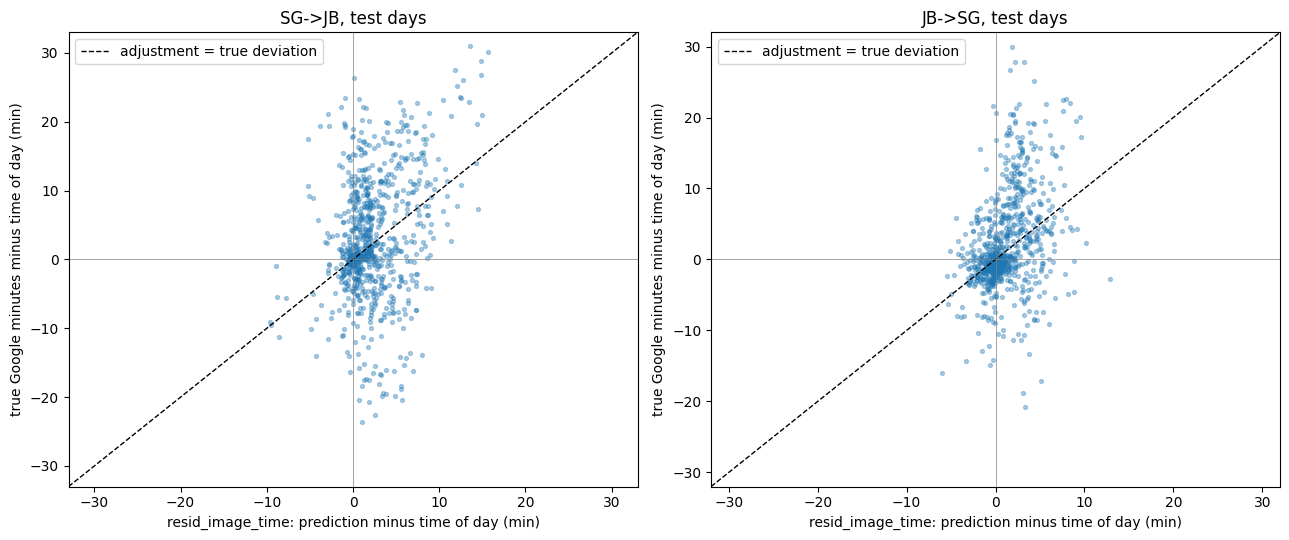

In [7]:
# Does the model's departure from the time-of-day baseline point the right way? For every variant and direction on the test
# days: the correlation between (prediction - baseline) and (true minutes - baseline), and the slope of the second on the
# first. 0 means the model adds nothing the clock does not already say; a slope near 1 means its adjustments are right-sized.
import matplotlib.pyplot as plt

def mean_pred(tag, d):
    return np.mean([preds_all[(tag, s)][d]["minutes"] for s in SEEDS], axis=0)      # seed-averaged minutes

rows = []
for tag in RUN:
    for d, (name, mcol, bcol) in enumerate(DIRS):
        base_min = tod_minutes(fit_df, test_eval, mcol)
        ok = test_eval[bcol].values >= 0
        adj, true_dev = (mean_pred(tag, d) - base_min)[ok], (test_eval[mcol].values - base_min)[ok]
        rows.append(dict(variant=tag, dir=name, adjustment_sd=adj.std(), correlation=np.corrcoef(adj, true_dev)[0, 1],
                         slope=np.polyfit(adj, true_dev, 1)[0] if adj.std() > 0 else np.nan))
print("Adjustment of each variant relative to time of day, test days (seed-averaged predictions)")
print(pd.DataFrame(rows).round(2).to_string(index=False))

for d, (name, mcol, bcol) in enumerate(DIRS):
    t_band, t_min = test_eval[bcol].values, test_eval[mcol].values
    tod = tod_minutes(fit_df, test_eval, mcol)
    table = []
    for b in range(N_BANDS):
        s = t_band == b
        if s.sum():
            table.append({"true band": BAND_LABELS[b], "n": int(s.sum()), "true min (mean)": t_min[s].mean(), "time of day": tod[s].mean(),
                          **{tag: mean_pred(tag, d)[s].mean() for tag in RUN}})
    print(f"\n{name}: mean predicted minutes by true band, test days")
    print(pd.DataFrame(table).round(1).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for d, (name, mcol, bcol) in enumerate(DIRS):
    tod = tod_minutes(fit_df, test_eval, mcol)
    true_dev, adj = test_eval[mcol].values - tod, mean_pred(best_image, d) - tod
    ax = axes[d]
    ax.scatter(adj, true_dev, s=8, alpha=0.35)
    lim = max(np.nanmax(np.abs(true_dev)), np.nanmax(np.abs(adj))) + 2
    ax.plot([-lim, lim], [-lim, lim], "k--", lw=1, label="adjustment = true deviation")
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel=f"{best_image}: prediction minus time of day (min)",
           ylabel="true Google minutes minus time of day (min)", title=f"{name}, test days")
    ax.legend()
plt.tight_layout()
plt.show()


## 8. Sample check
Test-day frames with the true Google minutes and the model's minutes: 6 random frames, the 6 biggest errors and the 6 longest real drive times. Set `CHECK_VARIANT` to look at another variant.

resid_image_time: loss residual, model input = FULL IMAGE


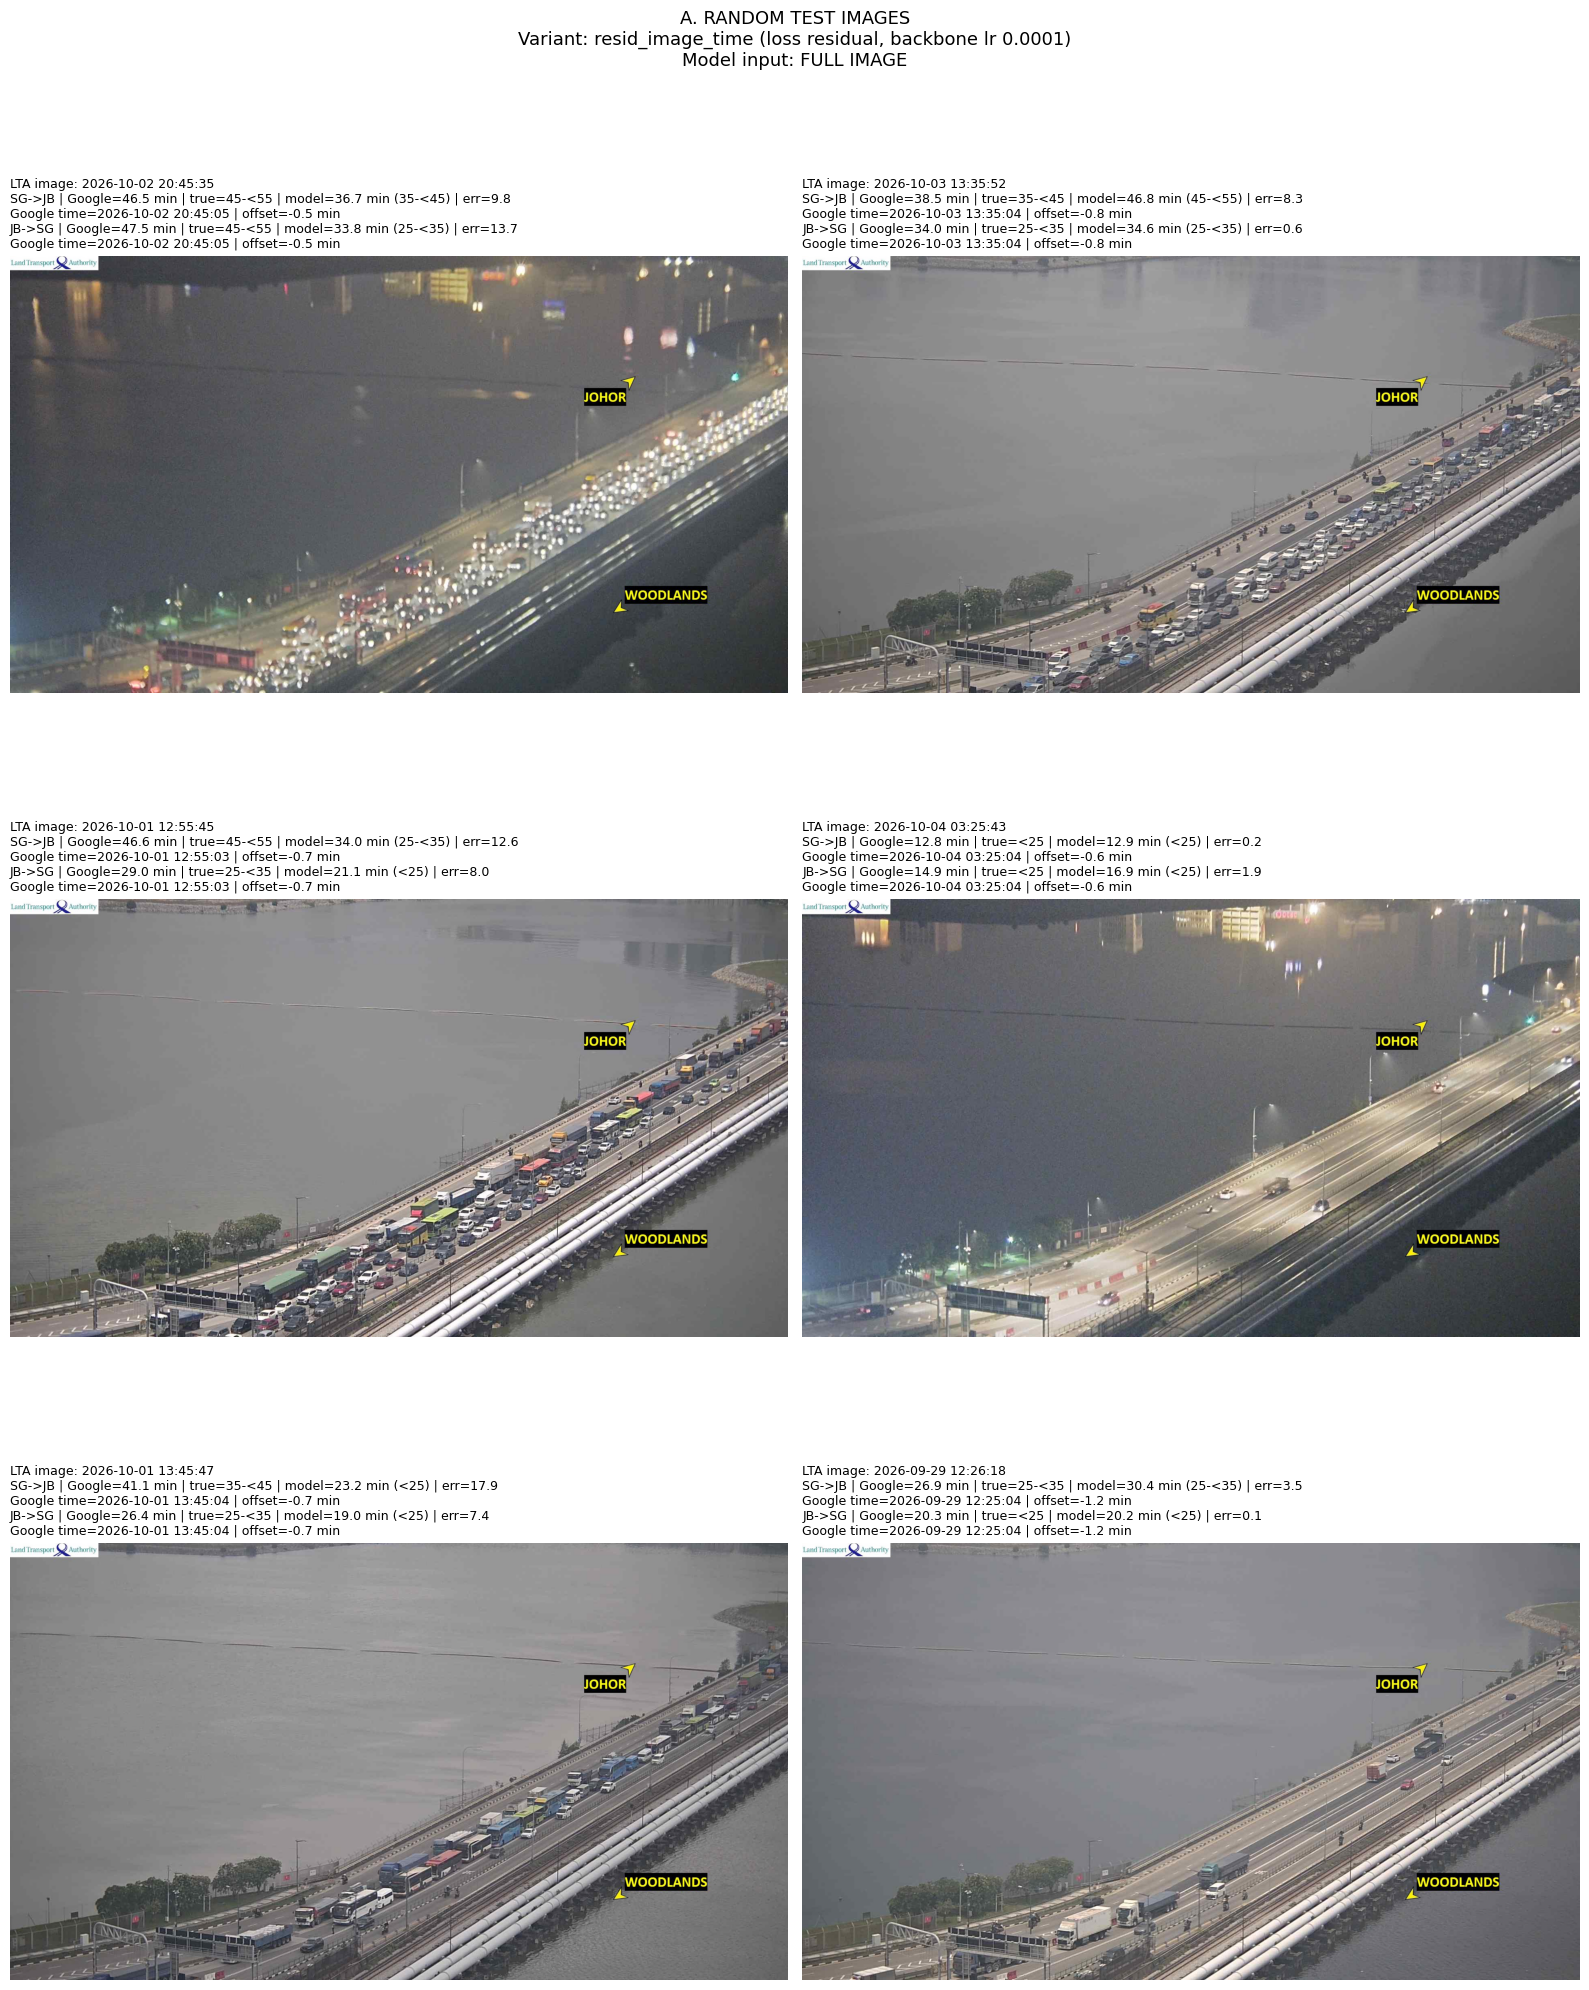

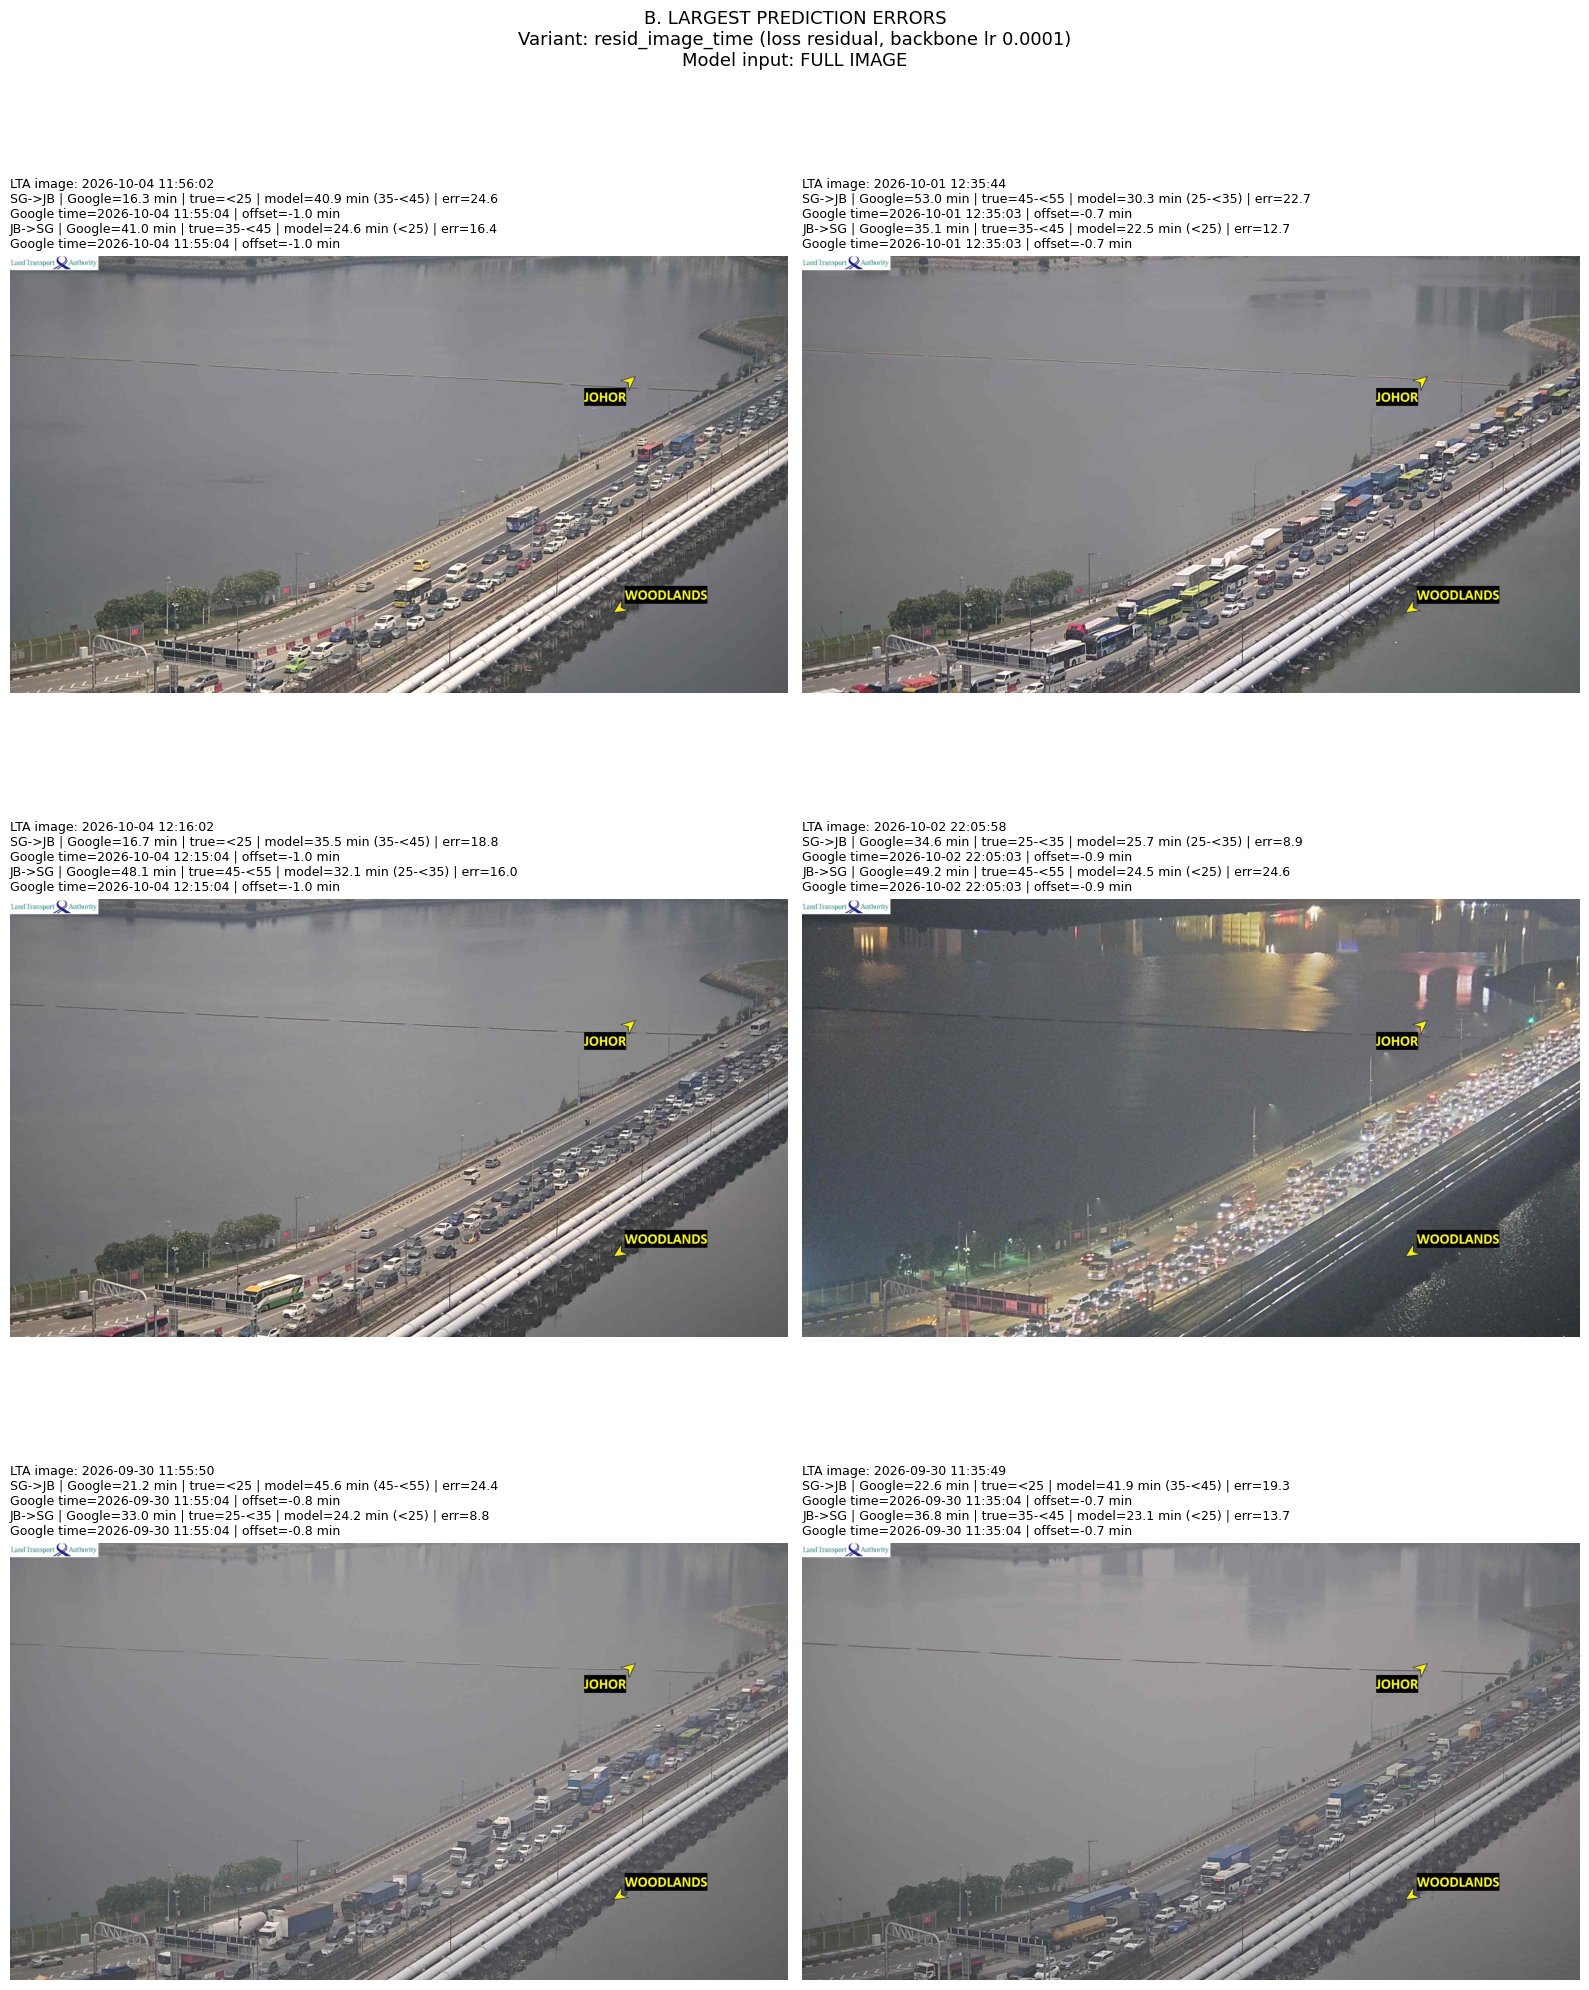

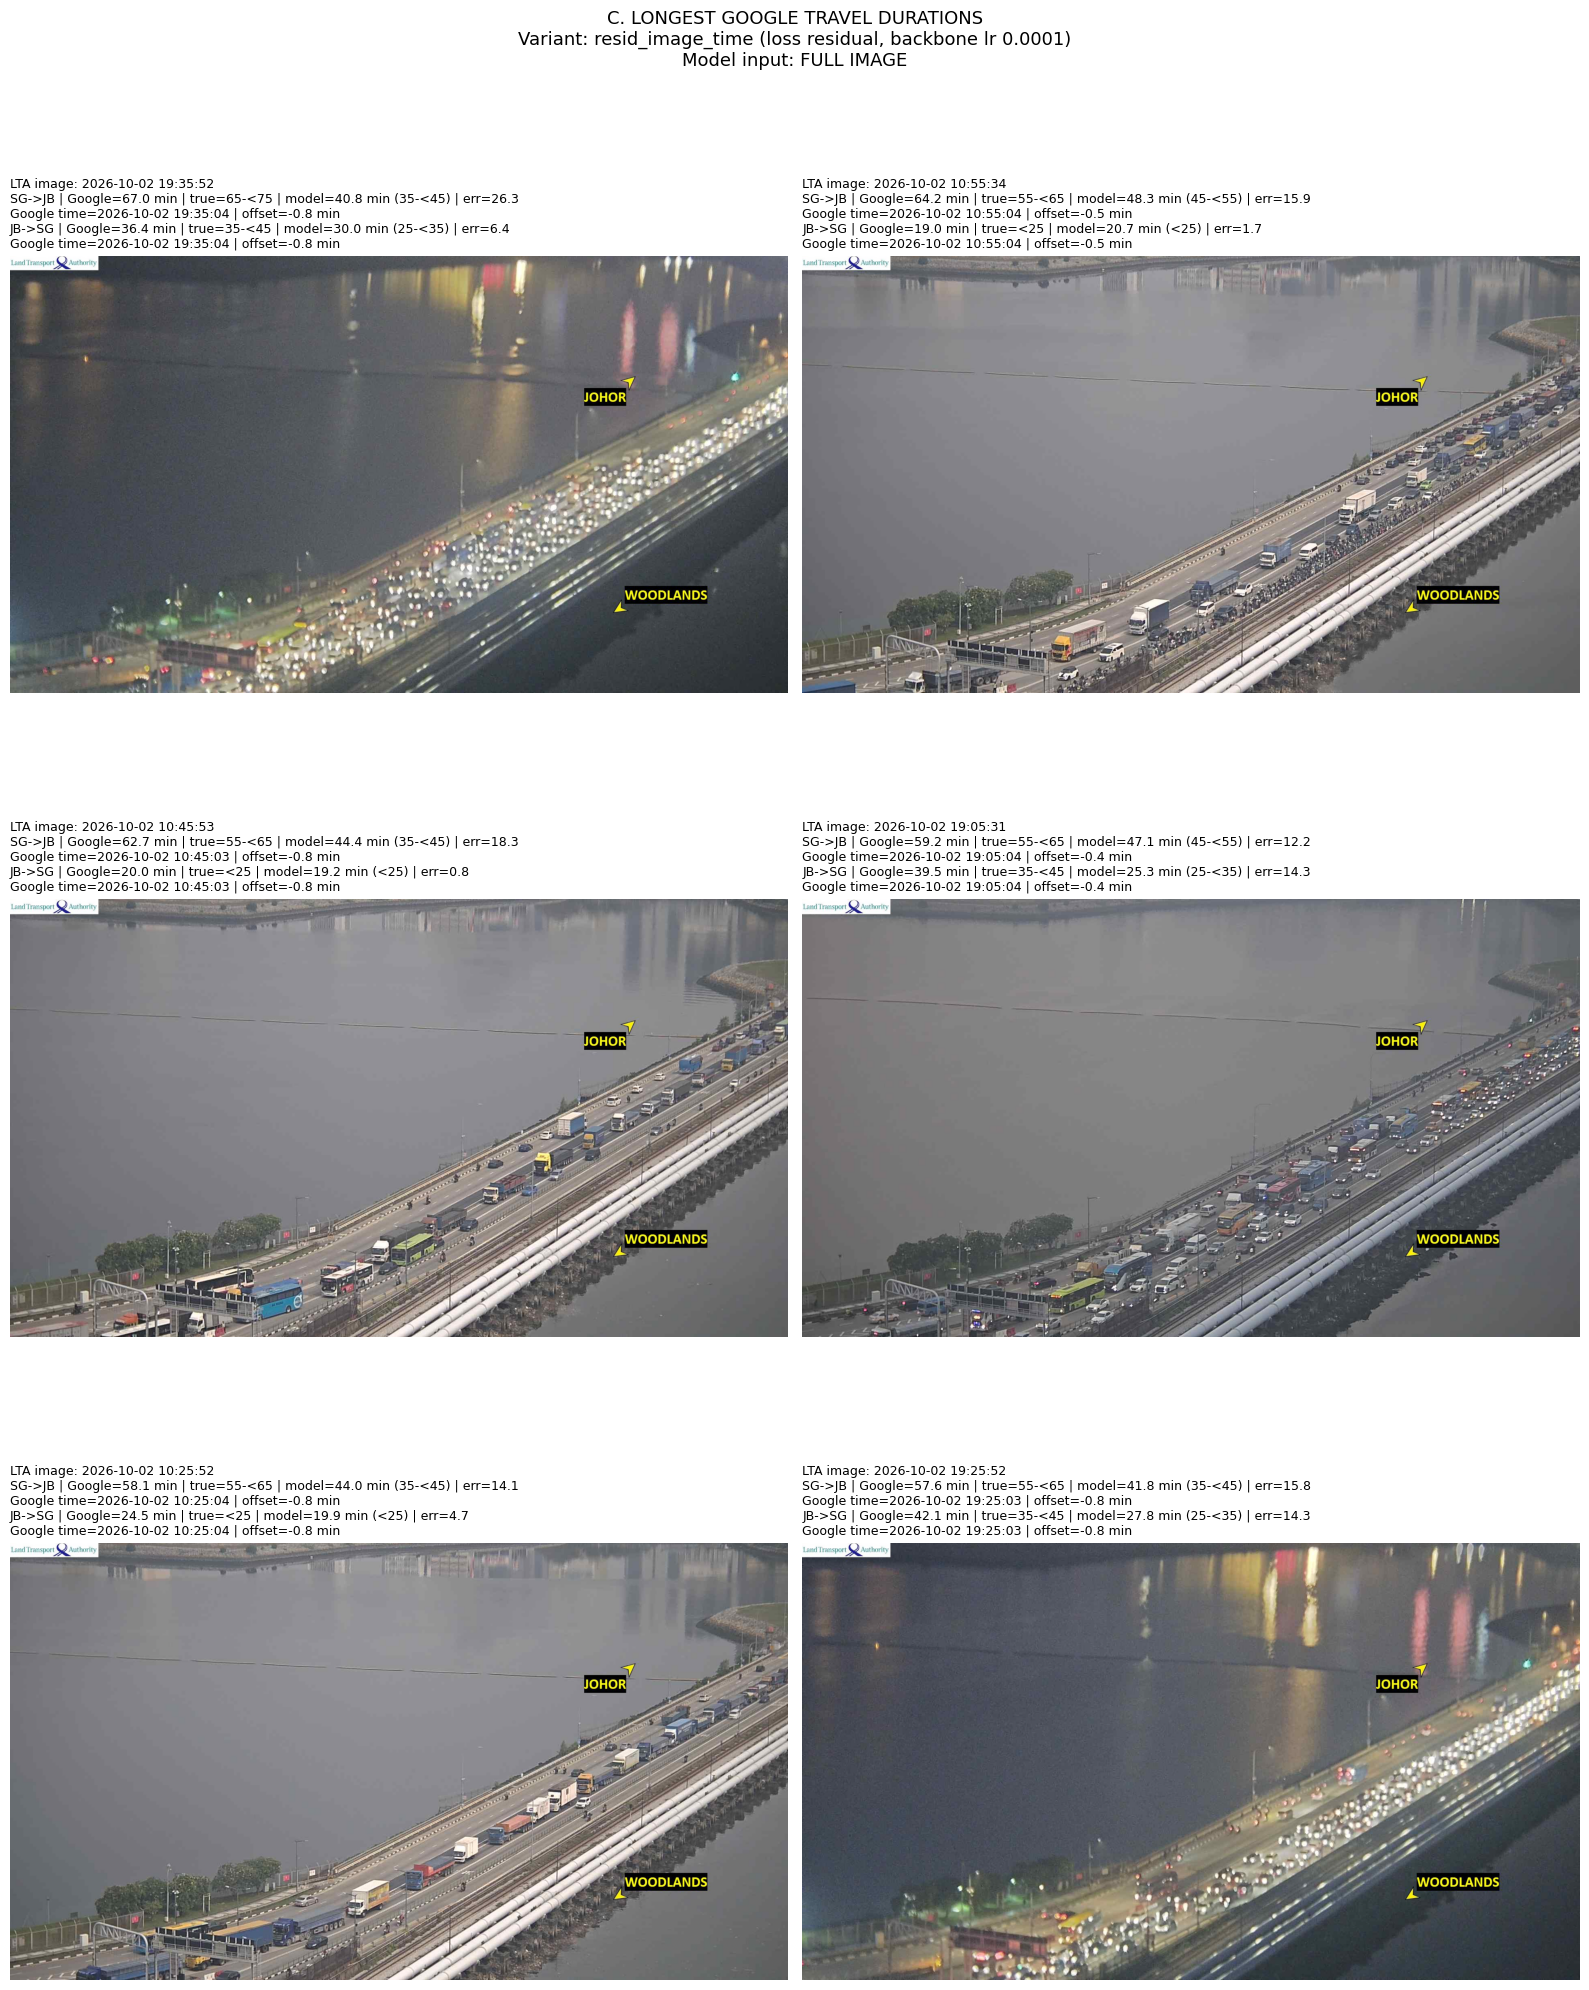


Manual QA sample: 18 unique frames


,ts,path,sg_jb_google_ts,sg_jb_align_offset_min,sg_jb_min,sg_jb_true_band,sg_jb_pred_band,sg_jb_model_min,sg_jb_abs_error_min,jb_sg_google_ts,jb_sg_align_offset_min,jb_sg_min,jb_sg_true_band,jb_sg_pred_band,jb_sg_model_min,jb_sg_abs_error_min,mean_abs_error_min
548,2026-10-02 20:45:35,/content/frames_2701/2701_20261002T204535.jpg,2026-10-02 20:45:05.704,-0.488,46.533,45-<55,35-<45,36.729,9.805,2026-10-02 20:45:05.704,-0.488,47.483,45-<55,25-<35,33.753,13.731,11.768
647,2026-10-03 13:35:52,/content/frames_2701/2701_20261003T133552.jpg,2026-10-03 13:35:04.241,-0.796,38.550,35-<45,45-<55,46.814,8.264,2026-10-03 13:35:04.241,-0.796,34.017,25-<35,25-<35,34.605,0.589,4.426
363,2026-10-01 12:55:45,/content/frames_2701/2701_20261001T125545.jpg,2026-10-01 12:55:03.867,-0.686,46.583,45-<55,25-<35,33.958,12.625,2026-10-01 12:55:03.867,-0.686,29.017,25-<35,<25,21.055,7.961,10.293
722,2026-10-04 03:25:43,/content/frames_2701/2701_20261004T032543.jpg,2026-10-04 03:25:04.137,-0.648,12.767,<25,<25,12.925,0.158,2026-10-04 03:25:04.137,-0.648,14.917,<25,<25,16.858,1.941,1.049
368,2026-10-01 13:45:47,/content/frames_2701/2701_20261001T134547.jpg,2026-10-01 13:45:04.248,-0.713,41.100,35-<45,<25,23.171,17.929,2026-10-01 13:45:04.248,-0.713,26.450,25-<35,<25,19.002,7.448,12.688
74,2026-09-29 12:26:18,/content/frames_2701/2701_20260929T122618.jpg,2026-09-29 12:25:04.062,-1.232,26.850,25-<35,25-<35,30.361,3.511,2026-09-29 12:25:04.062,-1.232,20.317,<25,<25,20.202,0.115,1.813
772,2026-10-04 11:56:02,/content/frames_2701/2701_20261004T115602.jpg,2026-10-04 11:55:04.248,-0.963,16.283,<25,35-<45,40.913,24.630,2026-10-04 11:55:04.248,-0.963,41.050,35-<45,<25,24.643,16.407,20.518
361,2026-10-01 12:35:44,/content/frames_2701/2701_20261001T123544.jpg,2026-10-01 12:35:03.951,-0.667,53.050,45-<55,25-<35,30.344,22.706,2026-10-01 12:35:03.951,-0.667,35.117,35-<45,<25,22.461,12.656,17.681
774,2026-10-04 12:16:02,/content/frames_2701/2701_20261004T121602.jpg,2026-10-04 12:15:04.198,-0.963,16.667,<25,35-<45,35.461,18.795,2026-10-04 12:15:04.198,-0.963,48.100,45-<55,25-<35,32.060,16.040,17.417
556,2026-10-02 22:05:58,/content/frames_2701/2701_20261002T220558.jpg,2026-10-02 22:05:03.935,-0.901,34.583,25-<35,25-<35,25.677,8.906,2026-10-02 22:05:03.935,-0.901,49.167,45-<55,<25,24.522,24.645,16.775



Saved: /content/manual_QA_sample.csv (18 frames), /content/detailed_test_predictions.csv (841 test frames)


In [8]:
import matplotlib.pyplot as plt

CHECK_VARIANT = best_image               # the best model that uses the picture; or any tag in RUN
N_EACH = 6                               # frames per group below
check_cfg = VARIANTS[CHECK_VARIANT]
view = ("NO IMAGE INPUT (hour and weekday only; the frame is shown for reference)" if not check_cfg["use_image"] else "FULL IMAGE" if check_cfg["crop"] is None else "YELLOW BOX / CROPPED REGION") + "".join(
    f" + {label}" for key, label in (("mask", "off-road masking"), ("equalize", "luminance equalisation"), ("grayscale", "grayscale"))
    if check_cfg[key])
print(f"{CHECK_VARIANT}: loss {check_cfg['loss']}, model input = {view}")

# Seed-averaged minutes (and class probabilities, for the ce / ordinal losses) of the checked variant on the test frames.
check_min = [np.mean([preds_all[(CHECK_VARIANT, s)][d]["minutes"] for s in SEEDS], axis=0) for d in range(2)]
check_probs = [None if preds_all[(CHECK_VARIANT, SEEDS[0])][d]["probs"] is None
               else np.mean([preds_all[(CHECK_VARIANT, s)][d]["probs"] for s in SEEDS], axis=0) for d in range(2)]
sample = test_eval.copy()
for d, (name, mcol, bcol) in enumerate(DIRS):
    k = mcol[:-len("_min")]
    sample[f"{k}_model_min"] = check_min[d]
    sample[f"{k}_pred_band"] = [BAND_LABELS[i] for i in np.digitize(check_min[d], BAND_EDGES)]       # band of the minute estimate
    sample[f"{k}_abs_error_min"] = np.abs(check_min[d] - sample[mcol])
    sample[f"{k}_true_band"] = [BAND_LABELS[int(b)] if b >= 0 else "NA" for b in sample[bcol]]
    if check_probs[d] is not None:
        sample[f"{k}_pred_confidence"] = check_probs[d].max(1)
        for c, label in enumerate(BAND_NAMES):
            sample[f"{k}_P_{label.replace('+', 'plus')}"] = check_probs[d][:, c]
sample["mean_abs_error_min"] = sample[["sg_jb_abs_error_min", "jb_sg_abs_error_min"]].mean(axis=1)
sample["max_actual_duration"] = sample[["sg_jb_min", "jb_sg_min"]].max(axis=1)
sample.to_csv(f"{OUT_DIR}/detailed_test_predictions.csv", index=False)

fmt_num = lambda x: "NA" if pd.isna(x) else f"{float(x):.1f}"
fmt_ts = lambda x: "NA" if pd.isna(x) else pd.Timestamp(x).strftime("%Y-%m-%d %H:%M:%S")

def title(row):
    lines = [f"LTA image: {fmt_ts(row['ts'])}"]
    for name, mcol, _ in DIRS:
        k = mcol[:-len("_min")]
        lines += [f"{name} | Google={fmt_num(row[mcol])} min | true={row[k + '_true_band']} | model={fmt_num(row[k + '_model_min'])} min "
                  f"({row[k + '_pred_band']}) | err={fmt_num(row[k + '_abs_error_min'])}",
                  f"Google time={fmt_ts(row[k + '_google_ts'])} | offset={fmt_num(row[k + '_align_offset_min'])} min"]
    return "\n".join(lines)

def show(indices, group_title):
    indices = list(indices)
    if not indices:
        return
    nrows = math.ceil(len(indices) / 2)
    fig, axes = plt.subplots(nrows, 2, figsize=(16, 7 * nrows), squeeze=False)
    axes = axes.reshape(-1)
    for ax, idx in zip(axes, indices):
        row = sample.iloc[idx]
        if not os.path.exists(row["path"]):
            ax.text(0.5, 0.5, f"IMAGE NOT FOUND\n{row['path']}", ha="center", va="center")
        else:
            img = Image.open(row["path"]).convert("RGB")
            W, H = img.size
            ax.imshow(img)
            if check_cfg["crop"] is not None:
                l, t, r, b = check_cfg["crop"]
                ax.add_patch(plt.Rectangle((l * W, t * H), (r - l) * W, (b - t) * H, fill=False, edgecolor="yellow", linewidth=2))
            ax.set_title(title(row), fontsize=9, loc="left")
            if all(p is not None for p in check_probs):
                probs_text = "\n\n".join(f"Probabilities {name}\n" + " | ".join(f"{lab}:{q:.2f}" for lab, q in zip(BAND_NAMES, check_probs[d][idx]))
                                         for d, (name, _, _) in enumerate(DIRS))
                ax.text(0.01, 0.01, probs_text, transform=ax.transAxes, fontsize=7, va="bottom", ha="left",
                        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
        ax.axis("off")
    for ax in axes[len(indices):]:
        ax.axis("off")
    fig.suptitle(f"{group_title}\nVariant: {CHECK_VARIANT} (loss {check_cfg['loss']}, backbone lr {check_cfg['lr_backbone']:g})\nModel input: {view}", fontsize=13, y=1.01)
    plt.tight_layout()
    plt.show()

random_idx = np.random.default_rng(42).choice(len(sample), size=min(N_EACH, len(sample)), replace=False)
worst_idx = sample["mean_abs_error_min"].nlargest(N_EACH).index.tolist()
longest_idx = sample["max_actual_duration"].nlargest(N_EACH).index.tolist()
show(random_idx, "A. RANDOM TEST IMAGES")
show(worst_idx, "B. LARGEST PREDICTION ERRORS")
show(longest_idx, "C. LONGEST GOOGLE TRAVEL DURATIONS")

# The frames shown above, with alignment, truth, prediction and (where the loss gives them) the band probabilities, for manual checking.
qa = sample.iloc[list(dict.fromkeys(list(random_idx) + worst_idx + longest_idx))]
qa_cols = (["ts", "path"] + [f"{k}_{c}" for k in ("sg_jb", "jb_sg") for c in
           ("google_ts", "align_offset_min", "min", "true_band", "pred_band", "model_min", "abs_error_min")]
           + ["mean_abs_error_min"] + [c for c in qa.columns if "_P_" in c])
qa[qa_cols].to_csv(f"{OUT_DIR}/manual_QA_sample.csv", index=False)
print(f"\nManual QA sample: {len(qa)} unique frames")
display(qa[qa_cols].round({c: 3 for c in qa[qa_cols].select_dtypes("number").columns}))
print(f"\nSaved: {OUT_DIR}/manual_QA_sample.csv ({len(qa)} frames), {OUT_DIR}/detailed_test_predictions.csv ({len(sample):,} test frames)")


## 9. Test 1: blind human ratings
**Rate what you see, nothing else.** For each frame give two ratings: the lanes heading to Johor (toward the JOHOR label) and the lanes heading to Singapore (toward the WOODLANDS label). Scale: 1 free flow (few vehicles, all moving), 2 light, 3 moderate (dense but moving), 4 heavy (stop-and-go, lanes mostly full), 5 jammed (bumper to bumper, standing). Use "can't tell" if you cannot see or cannot tell which carriageway is which. The frames are in random order and show no time or Google value.

**Step 1 (cell below): rater 1.** Builds the sample once, so every rater sees the same frames, and shows the form. It saves after every frame and resumes where you stopped.

In [9]:
# Test 1, step 1: a blind sample of test frames for people to rate. Each rater sees only the picture: no time, no Google minutes,
# no model output. Run this cell once per rater with RATER set to their name; the sample is saved so every rater sees the same frames.
import glob, io
import ipywidgets as widgets
from IPython.display import display, clear_output

N_LABEL = 150                     # test frames to rate (about 30-40 minutes for two ratings per frame)
RATER = "rater1"                  # change for each person: labels are saved to labels_<RATER>.csv
SAMPLE_FILE = f"{OUT_DIR}/blind_sample.csv"
LABEL_FILE = lambda r: f"{OUT_DIR}/labels_{r}.csv"
SCALE = [(0, "can't tell / not visible"), (1, "1  free flow: few vehicles, all moving"), (2, "2  light: some vehicles, moving"),
         (3, "3  moderate: dense, still moving"), (4, "4  heavy: stop-and-go, lanes mostly full"), (5, "5  jammed: bumper to bumper, standing")]

def make_sample(n=N_LABEL, seed=7):
    """n test frames spread evenly over five groups of increasing Google delay, in random order (so the order says nothing)."""
    gmax = test_eval[[m for _, m, _ in DIRS]].max(axis=1)
    group = pd.qcut(gmax, 5, labels=False, duplicates="drop")
    rng = np.random.default_rng(seed)
    picks = []
    for g in sorted(group.unique()):
        idx = np.where(group.values == g)[0]
        picks += list(rng.choice(idx, size=min(len(idx), n // 5), replace=False))
    picks = rng.permutation(picks)
    return pd.DataFrame({"id": np.arange(len(picks)), "path": test_eval["path"].values[picks]})

if os.path.exists(SAMPLE_FILE):
    blind = pd.read_csv(SAMPLE_FILE)
else:
    blind = make_sample()
    blind.to_csv(SAMPLE_FILE, index=False)
print(f"blind sample: {len(blind)} test frames ({SAMPLE_FILE})")

def read_ratings(path):
    """{id: (level toward Johor, level toward Singapore)} from a label file; 0 = can't tell."""
    if not os.path.exists(path):
        return {}
    return {int(r.id): (int(r.sg_jb_level), int(r.jb_sg_level)) for r in pd.read_csv(path).itertuples()}

def write_ratings(path, ratings, order):
    rows = [dict(id=i, path=order.set_index("id").loc[i, "path"], sg_jb_level=a, jb_sg_level=b) for i, (a, b) in sorted(ratings.items())]
    pd.DataFrame(rows, columns=["id", "path", "sg_jb_level", "jb_sg_level"]).to_csv(path, index=False)

def jpeg_bytes(path, width=1000):
    img = Image.open(path).convert("RGB")
    img = img.resize((width, int(img.height * width / img.width)))
    buf = io.BytesIO(); img.save(buf, "JPEG", quality=85)
    return buf.getvalue()

def labeller(rater):
    """Interactive form: shows one frame at a time, asks for two ratings, saves after every frame, resumes where you stopped."""
    path = LABEL_FILE(rater)
    ratings = read_ratings(path)
    pos = [next((i for i in range(len(blind)) if int(blind.id[i]) not in ratings), len(blind))]
    image = widgets.Image(format="jpeg", width=900)
    status = widgets.HTML()
    radios = [widgets.RadioButtons(options=[(t, v) for v, t in SCALE], value=None, layout=widgets.Layout(width="340px")) for _ in range(2)]
    titles = ["Traffic heading to JOHOR (the lanes moving toward the JOHOR label)", "Traffic heading to SINGAPORE (the lanes moving toward the WOODLANDS label)"]
    back, save = widgets.Button(description="Back"), widgets.Button(description="Save and next", button_style="primary")
    box = widgets.VBox([status, image, widgets.HBox([widgets.VBox([widgets.HTML(f"<b>{t}</b>"), r]) for t, r in zip(titles, radios)]), widgets.HBox([back, save])])
    def refresh():
        if pos[0] >= len(blind):
            image.value = b""; status.value = f"<b>Finished: {len(ratings)} frames rated by {rater}.</b> Labels are in {path} (download it to keep it)."
            for r in radios: r.disabled = True
            save.disabled = True
            return
        fid = int(blind.id[pos[0]])
        image.value = jpeg_bytes(blind.path[pos[0]])
        prior = ratings.get(fid, (None, None))
        radios[0].value, radios[1].value = prior
        status.value = f"{rater}: frame {pos[0] + 1} of {len(blind)}  ({len(ratings)} rated). Judge only what you SEE; do not guess from the time of day."
    def on_save(_):
        if radios[0].value is None or radios[1].value is None:
            status.value = "<b style='color:#b00'>Choose a level for both directions (or 'can't tell').</b>"
            return
        ratings[int(blind.id[pos[0]])] = (int(radios[0].value), int(radios[1].value))
        write_ratings(path, ratings, blind)
        pos[0] += 1
        refresh()
    def on_back(_):
        pos[0] = max(0, pos[0] - 1)
        for r in radios: r.disabled = False
        save.disabled = False
        refresh()
    save.on_click(on_save); back.on_click(on_back)
    refresh()
    return box

display(widgets.HTML("<b>Rating scale</b> (rate each carriageway separately, from the picture only):<br>" + "<br>".join(t for _, t in SCALE)))
display(labeller(RATER))


blind sample: 150 test frames (/content/blind_sample.csv)


HTML(value="<b>Rating scale</b> (rate each carriageway separately, from the picture only):<br>can't tell / not…

**Step 2: build the file for the second rater.** One HTML file with the blind sample inside it: no Colab, Google access or internet needed to rate. It holds only pictures, in an order different from rater 1's. Edit `BRIEFING` first so that it matches what the team agreed about the two carriageways. The file is rebuilt only if the sample changes or `REBUILD_KIT = True`.

In [17]:
# Test 1, step 2: a second independent rater. A self-contained HTML file with the blind sample inside it. The rater opens it in any browser (no Colab, no
# Google access, no internet), rates the frames, and downloads a small CSV. The file holds only pictures: no time, no file names, no
# Google minutes, no model output and none of rater 1's ratings. The order is different from the one rater 1 saw.
import base64, json

KIT_RATER = "rater2"                       # name used for the labels file
KIT_SEED = 202                             # a different random order from rater 1's
KIT_WIDTH, KIT_QUALITY = 800, 78           # picture size in the file (about 60 KB per frame)
BRIEFING = ("Each picture shows the causeway between the Singapore and Malaysian immigration booths. Rate the vehicles on each carriageway "
            "separately: the lanes moving toward the JOHOR label and the lanes moving toward the WOODLANDS label. Judge only what you can see "
            "in the picture; do not guess from the lighting. Rate each picture on its own. If you cannot see a carriageway, or cannot tell "
            "which one is which, choose \"can't tell\".")     # edit so that it matches what the team has agreed, before rating starts

KIT_TEMPLATE = r"""<!doctype html><html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>Congestion rating</title>
<style>
body{font-family:Arial,Helvetica,sans-serif;margin:0;background:#f4f6f8;color:#1b2a41}
#app{max-width:1500px;margin:0 auto;padding:12px 16px}
#main{display:flex;gap:14px;align-items:flex-start;flex-wrap:wrap}
#left{flex:2 1 640px;min-width:0}#right{flex:1 1 320px;min-width:300px}
h1{font-size:20px;margin:6px 0}
.box{background:#fff;border:1px solid #c9d1d9;border-radius:6px;padding:10px 14px;margin:10px 0;font-size:14px;line-height:1.45}
.scale div{margin:2px 0}
img{width:100%;border:1px solid #c9d1d9;border-radius:4px;display:block;margin:0}
.col{background:#fff;border:1px solid #c9d1d9;border-radius:6px;padding:8px 12px;margin-bottom:10px}
.col b{display:block;margin-bottom:6px}
label{display:block;margin:4px 0;cursor:pointer;font-size:14px}
button{font-size:15px;padding:9px 16px;margin:6px 8px 6px 0;border:1px solid #1b2a41;background:#fff;border-radius:5px;cursor:pointer}
button.primary{background:#1b2a41;color:#fff}
#bar{height:8px;background:#dde3ea;border-radius:4px;overflow:hidden}#fill{height:8px;background:#2a9d8f;width:0}
#msg{min-height:20px;color:#b00;font-size:14px}
</style></head><body><div id="app">
<h1>Rate the congestion you can see</h1>
<details class="box" id="help"><summary><b>Instructions and rating scale</b> (click to hide)</summary><div id="brief" style="margin:6px 0"></div><div class="scale" id="scale"></div></details>
<div id="bar"><div id="fill"></div></div>
<div id="status" class="box"></div>
<div id="main"><div id="left"><img id="frame" alt="camera frame"></div>
<div id="right"><div class="col" id="g0"></div><div class="col" id="g1"></div><div id="msg"></div>
<button id="back">Back</button><button id="save" class="primary">Save and next</button><br>
<button id="first">Go to first unrated</button><button id="dl">Download my ratings (CSV)</button></div></div>
<div class="box" style="font-size:13px">Your ratings are kept in this browser as you go, so you can close the page and come back to this same file. When you have finished, click <b>Download my ratings (CSV)</b> and send the file back. You can download at any time.</div>
</div>
<script>
const ITEMS=__ITEMS__, RATER=__RATER__, BRIEF=__BRIEF__, SCALE=__SCALE__, TITLES=__TITLES__;
const KEY="kit_"+RATER+"_"+ITEMS.length+"_"+ITEMS[0].id;
let ratings={}; try{ratings=JSON.parse(localStorage.getItem(KEY)||"{}")}catch(e){}
let pos=0;
const $=id=>document.getElementById(id);
$("brief").textContent=BRIEF;
$("scale").innerHTML="<b>Rating scale</b> (each carriageway separately)"+SCALE.filter(s=>s[0]>0).map(s=>"<div>"+s[1]+"</div>").join("");
[0,1].forEach(g=>{$("g"+g).innerHTML="<b>"+TITLES[g]+"</b>"+SCALE.map(s=>'<label><input type="radio" name="r'+g+'" value="'+s[0]+'"> '+s[1]+"</label>").join("")});
const getv=g=>{const c=document.querySelector('input[name="r'+g+'"]:checked');return c?parseInt(c.value):null};
const setv=(g,v)=>{document.querySelectorAll('input[name="r'+g+'"]').forEach(r=>{r.checked=(v!==null&&parseInt(r.value)===v)})};
const done=()=>Object.keys(ratings).length;
function persist(){try{localStorage.setItem(KEY,JSON.stringify(ratings))}catch(e){}}
function show(){
  if(pos>=ITEMS.length){$("status").textContent="Finished: "+done()+" of "+ITEMS.length+" pictures rated. Click Download my ratings (CSV) and send the file back.";$("frame").style.display="none";$("save").disabled=true;}
  else{const it=ITEMS[pos];$("frame").style.display="block";$("frame").src=it.img;$("save").disabled=false;
    const p=ratings[it.id]||[null,null];setv(0,p[0]);setv(1,p[1]);
    $("status").textContent="Picture "+(pos+1)+" of "+ITEMS.length+"  ("+done()+" rated)";}
  $("fill").style.width=(100*done()/ITEMS.length)+"%";$("msg").textContent="";
}
function csv(){return "id,sg_jb_level,jb_sg_level\n"+Object.keys(ratings).map(Number).sort((a,b)=>a-b).map(i=>i+","+ratings[i][0]+","+ratings[i][1]).join("\n")+"\n"}
$("save").onclick=()=>{const a=getv(0),b=getv(1);
  if(a===null||b===null){$("msg").textContent="Choose a level for both carriageways (or \"can't tell\").";return}
  ratings[ITEMS[pos].id]=[a,b];persist();$("help").open=false;pos++;window.scrollTo(0,0);show()};
$("back").onclick=()=>{pos=Math.max(0,pos-1);window.scrollTo(0,0);show()};
$("first").onclick=()=>{const i=ITEMS.findIndex(it=>!(it.id in ratings));pos=i<0?ITEMS.length:i;show()};
$("dl").onclick=()=>{const blob=new Blob([csv()],{type:"text/csv"});const a=document.createElement("a");a.href=URL.createObjectURL(blob);
  a.download="kit_ratings_"+RATER+".csv";document.body.appendChild(a);a.click();a.remove()};
document.addEventListener("keydown",e=>{if(e.key==="Enter"&&!$("save").disabled)$("save").click()});
pos=Math.max(0,ITEMS.findIndex(it=>!(it.id in ratings)));if(ITEMS.findIndex(it=>!(it.id in ratings))<0)pos=ITEMS.length;
$("help").open=(done()===0);
show();
</script></body></html>"""

def kit_jpeg(path):
    img = Image.open(path).convert("RGB")
    img = img.resize((KIT_WIDTH, int(img.height * KIT_WIDTH / img.width)))
    buf = io.BytesIO(); img.save(buf, "JPEG", quality=KIT_QUALITY)
    return "data:image/jpeg;base64," + base64.b64encode(buf.getvalue()).decode()

def build_rater_kit(rater=KIT_RATER, seed=KIT_SEED):
    """Writes rater_kit_<rater>.html with every blind-sample picture inside it, in an order of its own. Returns the file path."""
    order = blind.sample(frac=1, random_state=seed).reset_index(drop=True)
    items = [{"id": int(r.id), "img": kit_jpeg(r.path)} for r in order.itertuples()]
    titles = ["Traffic heading to JOHOR (the lanes moving toward the JOHOR label)", "Traffic heading to SINGAPORE (the lanes moving toward the WOODLANDS label)"]
    html = (KIT_TEMPLATE.replace("__ITEMS__", json.dumps(items)).replace("__RATER__", json.dumps(rater)).replace("__BRIEF__", json.dumps(BRIEFING))
            .replace("__SCALE__", json.dumps(SCALE)).replace("__TITLES__", json.dumps(titles)))
    out = f"{OUT_DIR}/rater_kit_{rater}.html"
    with open(out, "w", encoding="utf8") as f:
        f.write(html)
    with open(out + ".sample", "w") as f:
        f.write(sample_signature())
    print(f"{out}: {len(items)} pictures, {os.path.getsize(out) / 1e6:.1f} MB. Send this one file to {rater}; do not send any labels, the model output or the Google minutes.")
    return out

def sample_signature():
    """Identifies the blind sample, so a kit built for a different sample is never reused."""
    import hashlib
    return hashlib.md5(json.dumps([blind.id.tolist(), blind.path.tolist()]).encode()).hexdigest()

def import_kit_labels(csv_path, rater=KIT_RATER, overwrite=False):
    """Turns the CSV the rater downloaded into labels_<rater>.csv, ready for the scoring cell."""
    got = pd.read_csv(csv_path)
    assert {"id", "sg_jb_level", "jb_sg_level"} <= set(got.columns), "this does not look like a kit CSV"
    unknown = set(got.id) - set(blind.id)
    assert not unknown, f"ids not in the blind sample: {sorted(unknown)[:5]}"
    assert got.id.is_unique, "duplicate ids"
    assert got[["sg_jb_level", "jb_sg_level"]].isin(range(6)).all().all(), "levels must be 0-5"
    target = LABEL_FILE(rater)
    if os.path.exists(target) and not overwrite:
        raise FileExistsError(f"{target} exists; pass overwrite=True if you really want to replace it")
    got["path"] = got.id.map(blind.set_index("id")["path"])
    got[["id", "path", "sg_jb_level", "jb_sg_level"]].sort_values("id").to_csv(target, index=False)
    print(f"{target}: {len(got)} of {len(blind)} frames from {rater}; {int((got[['sg_jb_level', 'jb_sg_level']] == 0).sum().sum())} 'can't tell' ratings")

REBUILD_KIT = True                        # True to build the file again (for example after changing BRIEFING)
KIT_FILE = f"{OUT_DIR}/rater_kit_{KIT_RATER}.html"
if REBUILD_KIT or not os.path.exists(KIT_FILE) or not os.path.exists(KIT_FILE + ".sample") or open(KIT_FILE + ".sample").read() != sample_signature():
    build_rater_kit()
    try:                                   # in Colab the file is also downloaded, ready to send to the second rater
        from google.colab import files
        files.download(KIT_FILE)
    except Exception:
        pass
else:
    print(f"{KIT_FILE} already matches the blind sample ({os.path.getsize(KIT_FILE) / 1e6:.1f} MB); set REBUILD_KIT = True to build it again.")


/content/rater_kit_rater2.html: 150 pictures, 9.5 MB. Send this one file to rater2; do not send any labels, the model output or the Google minutes.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Step 3: import the second rater's ratings.** After the rater has finished, they download `kit_ratings_rater2.csv`. Put it in `/content` and run this cell: it creates `labels_rater2.csv` (the same format as rater 1's). It does nothing until the file is there.

In [19]:
# Test 1, step 3: bring the second rater's ratings in. Nothing happens until their file is in place.
KIT_CSV = f"{OUT_DIR}/kit_ratings_{KIT_RATER}.csv"
if os.path.exists(LABEL_FILE(KIT_RATER)):
    print(f"{LABEL_FILE(KIT_RATER)} already exists, so {KIT_RATER}'s ratings are in use. (To replace them: import_kit_labels(KIT_CSV, overwrite=True))")
elif os.path.exists(KIT_CSV):
    import_kit_labels(KIT_CSV)
else:
    print(f"No ratings from {KIT_RATER} yet. When {os.path.basename(KIT_CSV)} comes back, put it in {OUT_DIR} (Colab: the Files pane, or "
          "run  from google.colab import files; files.upload() ) and run this cell again.")


/content/labels_rater2.csv: 150 of 150 frames from rater2; 2 'can't tell' ratings


### Step 5: score against the ratings
Needs at least one label file; with two raters it also prints their agreement (rank correlation and quadratic weighted kappa). The table compares the Google minutes themselves, the time-of-day baseline and every model with the human level (the mean of the raters). The pass criteria are applied to the best model that uses the picture. **Set them at the top of the cell before looking at any result.**

In [20]:
# Test 1, step 5: score the models against the human ratings. Fix the pass criteria BEFORE you look at any result.
PASS_AUC = 0.90               # top (levels 4-5) vs bottom (levels 1-2) frames: chance of ranking the congested one higher
PASS_AUC_MATCHED = 0.80       # the same, using only pairs whose time-of-day baselines differ by at most CLOCK_TOL minutes
PASS_PARTIAL_RHO = 0.50       # rank correlation with the human level after removing what the time-of-day baseline explains
CLOCK_TOL = 3.0

def spearman(a, b):
    return float(pd.Series(a).rank().corr(pd.Series(b).rank()))

def partial_spearman(x, y, z):
    """Rank correlation of x and y after removing the linear effect of z (the clock baseline) from both."""
    rx, ry, rz = [pd.Series(v).rank().values.astype(float) for v in (x, y, z)]
    A = np.c_[np.ones_like(rz), rz]
    ex, ey = [v - A @ np.linalg.lstsq(A, v, rcond=None)[0] for v in (rx, ry)]
    return float(np.corrcoef(ex, ey)[0, 1]) if ex.std() > 1e-9 and ey.std() > 1e-9 else 0.0

def auc_top_vs_bottom(score, level, clock=None, tol=CLOCK_TOL):
    """Chance that a top-level frame (rating >= 4) scores higher than a bottom-level one (<= 2); ties count half.
    With clock given, only pairs whose baselines are within tol minutes are compared. Returns (auc, number of pairs)."""
    top, bot = level >= 4, level <= 2
    sp, sn = score[top], score[bot]
    if len(sp) == 0 or len(sn) == 0:
        return np.nan, 0
    wins = (sp[:, None] > sn[None, :]) + 0.5 * (sp[:, None] == sn[None, :])
    keep = np.ones_like(wins, bool) if clock is None else np.abs(clock[top][:, None] - clock[bot][None, :]) <= tol
    return (float(wins[keep].sum() / keep.sum()) if keep.sum() else np.nan), int(keep.sum())

def weighted_kappa(a, b, k=6):
    """Quadratic weighted kappa between two raters (levels 1-5)."""
    a, b = np.asarray(a, int), np.asarray(b, int)
    O = np.zeros((k, k)); np.add.at(O, (a, b), 1)
    E = np.outer(np.bincount(a, minlength=k), np.bincount(b, minlength=k)) / len(a)
    W = (np.subtract.outer(np.arange(k), np.arange(k)) ** 2) / (k - 1) ** 2
    return float(1 - (W * O).sum() / (W * E).sum())

files = sorted(glob.glob(LABEL_FILE("*")))
if not files:
    print(f"No label files in {OUT_DIR} yet. Rate the frames in the previous cell (one file per rater), then run this cell again.")
else:
    raters = {os.path.basename(f)[len("labels_"):-4]: pd.read_csv(f) for f in files}
    pos_of = {p: i for i, p in enumerate(test_eval["path"])}
    # one level per frame and direction: the mean over raters, ignoring "can't tell" (0)
    levels = {}
    for name, df_r in raters.items():
        for col, key in (("sg_jb_level", 0), ("jb_sg_level", 1)):
            for r in df_r.itertuples():
                v = getattr(r, col)
                if v > 0:
                    levels.setdefault((pos_of[r.path], key), []).append(v)
    print(f"raters: {list(raters)}; frames rated: {len({p for p, _ in levels})}")
    if len(raters) > 1:
        names = list(raters)
        for col, nm in (("sg_jb_level", "toward Johor"), ("jb_sg_level", "toward Singapore")):
            m = raters[names[0]].merge(raters[names[1]], on="id", suffixes=("_a", "_b"))
            m = m[(m[col + "_a"] > 0) & (m[col + "_b"] > 0)]
            print(f"agreement between {names[0]} and {names[1]}, {nm}: n={len(m)}, Spearman {spearman(m[col + '_a'], m[col + '_b']):.2f}, "
                  f"weighted kappa {weighted_kappa(m[col + '_a'], m[col + '_b']):.2f}")
    else:
        print("only one rater so far: add a second person (RATER = another name) to measure how reliable the ratings are")

    tod = {d: tod_minutes(fit_df, test_eval, mcol) for d, (_, mcol, _) in enumerate(DIRS)}
    model_min = {tag: [np.mean([preds_all[(tag, s)][d]["minutes"] for s in SEEDS], axis=0) for d in range(2)] for tag in RUN}
    rows = []
    for target in ("SG->JB", "JB->SG", "worse of the two"):
        ds = [0] if target == "SG->JB" else [1] if target == "JB->SG" else [0, 1]
        frames_ok = sorted(p for p in {p for p, _ in levels} if all((p, d) in levels for d in ds))
        if len(frames_ok) < 10:
            continue
        lv = np.array([max(np.mean(levels[(p, d)]) for d in ds) for p in frames_ok])
        pick = lambda a: np.asarray(a)[frames_ok]
        scorers = {"Google minutes (the label)": np.max([pick(test_eval[DIRS[d][1]].values) for d in ds], axis=0),
                   "time of day (training days)": np.max([pick(tod[d]) for d in ds], axis=0),
                   **{tag: np.max([pick(model_min[tag][d]) for d in ds], axis=0) for tag in RUN}}
        clock = np.max([pick(tod[d]) for d in ds], axis=0)
        for name, sc in scorers.items():
            auc_all, _ = auc_top_vs_bottom(sc, lv)
            auc_m, n_pairs = auc_top_vs_bottom(sc, lv, clock)
            rows.append(dict(target=target, scorer=name, frames=len(frames_ok), spearman=spearman(sc, lv), partial_spearman_given_clock=partial_spearman(sc, lv, clock),
                             auc_top_vs_bottom=auc_all, auc_clock_matched=auc_m, matched_pairs=n_pairs))
    if rows:
        human = pd.DataFrame(rows)
        human.to_csv(f"{OUT_DIR}/human_label_scores.csv", index=False)
        print(f"\n{'=' * 80}\nMODELS AGAINST THE HUMAN RATINGS (test frames, rated blind)\n{'=' * 80}")
        print("spearman = rank correlation with the human level | partial = after removing what the time-of-day baseline explains")
        print("auc_top_vs_bottom = chance a level 4-5 frame outscores a level 1-2 frame | auc_clock_matched = the same for pairs with similar time-of-day baselines\n")
        print(human.round(2).to_string(index=False))
        print(f"\nPASS CRITERIA for the best model that uses the picture ({best_image}): AUC >= {PASS_AUC}, clock-matched AUC >= {PASS_AUC_MATCHED}, partial rho >= {PASS_PARTIAL_RHO}")
        for _, r in human[human.scorer == best_image].iterrows():
            ok = [r.auc_top_vs_bottom >= PASS_AUC, r.auc_clock_matched >= PASS_AUC_MATCHED, r.partial_spearman_given_clock >= PASS_PARTIAL_RHO]
            print(f"  {r.target:<18} AUC {r.auc_top_vs_bottom:.2f} [{'pass' if ok[0] else 'fail'}]  clock-matched AUC {r.auc_clock_matched:.2f} "
                  f"[{'pass' if ok[1] else 'fail'}]  partial rho {r.partial_spearman_given_clock:.2f} [{'pass' if ok[2] else 'fail'}]")
    else:
        print("fewer than 10 frames rated in a direction so far; keep rating.")


raters: ['rater1', 'rater2']; frames rated: 150
agreement between rater1 and rater2, toward Johor: n=146, Spearman 0.53, weighted kappa 0.48
agreement between rater1 and rater2, toward Singapore: n=150, Spearman 0.90, weighted kappa 0.91

MODELS AGAINST THE HUMAN RATINGS (test frames, rated blind)
spearman = rank correlation with the human level | partial = after removing what the time-of-day baseline explains
auc_top_vs_bottom = chance a level 4-5 frame outscores a level 1-2 frame | auc_clock_matched = the same for pairs with similar time-of-day baselines

          target                      scorer  frames  spearman  partial_spearman_given_clock  auc_top_vs_bottom  auc_clock_matched  matched_pairs
          SG->JB  Google minutes (the label)     149      0.33                          0.18               0.91               0.76             58
          SG->JB time of day (training days)     149      0.28                          0.00               0.81               0.43             5

### Step 6: each rater separately, and the direction check
The selected model scored against each rater on their own and against their average, with the same pass criteria: do both raters lead to the same conclusion? The direction check shows whether Google and the model agree better with the *other* rating column; if an SG→JB row is higher under "rated toward Singapore", the carriageways were probably swapped for that rater.

In [21]:
# Test 1, step 6: score the selected model against each rater on their own, and check that the two carriageways were assigned to the right directions.
def score_each_rater(model=None):
    """The selected model scored against each rater on their own and against the average of the raters, with the same pass criteria as the
    scoring cell. Do the raters lead to the same conclusion? Run after the scoring cell (it defines the metric functions)."""
    model = model or best_image
    pos_of = {p: i for i, p in enumerate(test_eval["path"])}
    mm = [np.mean([preds_all[(model, s)][d]["minutes"] for s in SEEDS], axis=0) for d in range(2)]
    clock = [tod_minutes(fit_df, test_eval, DIRS[d][1]) for d in range(2)]
    raters = {os.path.basename(f)[len("labels_"):-4]: pd.read_csv(f) for f in sorted(glob.glob(LABEL_FILE("*")))}
    raters = {n: df_r for n, df_r in raters.items() if "path" in df_r.columns}        # skip anything that is not a label file
    levels = {}                                                   # (rater, direction) -> {frame position: level}
    for name, df_r in raters.items():
        for d, col in enumerate(("sg_jb_level", "jb_sg_level")):
            levels[(name, d)] = {pos_of[r.path]: getattr(r, col) for r in df_r.itertuples() if getattr(r, col) > 0}
    sets = dict(raters.items())
    rows = []
    for who in list(raters) + (["average of raters"] if len(raters) > 1 else []):
        for d, (dname, _, _) in enumerate(DIRS):
            if who == "average of raters":
                pool = {}
                for name in raters:
                    for p, v in levels[(name, d)].items():
                        pool.setdefault(p, []).append(v)
                lv_map = {p: float(np.mean(v)) for p, v in pool.items()}
            else:
                lv_map = {p: float(v) for p, v in levels[(who, d)].items()}
            frames_ok = sorted(lv_map)
            if len(frames_ok) < 10:
                continue
            lv = np.array([lv_map[p] for p in frames_ok]); sc, ck = mm[d][frames_ok], clock[d][frames_ok]
            auc_all, _ = auc_top_vs_bottom(sc, lv); auc_m, n_pairs = auc_top_vs_bottom(sc, lv, ck)
            part = partial_spearman(sc, lv, ck)
            rows.append(dict(rater=who, direction=dname, frames=len(frames_ok), spearman=spearman(sc, lv), partial_spearman=part, auc=auc_all, auc_clock_matched=auc_m,
                             matched_pairs=n_pairs, passes=int(auc_all >= PASS_AUC) + int(auc_m >= PASS_AUC_MATCHED) + int(part >= PASS_PARTIAL_RHO)))
    table = pd.DataFrame(rows)
    table.to_csv(f"{OUT_DIR}/score_by_rater.csv", index=False)
    print(f"{model} against each rater (passes = how many of the 3 criteria are met):")
    print(table.round(2).to_string(index=False))
    return table

def direction_check():
    """If the rater's 'toward Johor' and 'toward Singapore' columns were swapped for some frames (or the carriageways were hard to tell apart),
    the Google minutes and the models agree better with the OTHER column. Each cell is a Spearman correlation on the frames rated in both."""
    rho = lambda a, b: float(pd.Series(a).rank().corr(pd.Series(b).rank()))
    pos_of = {p: i for i, p in enumerate(test_eval["path"])}
    for f in sorted(glob.glob(LABEL_FILE("*"))):
        df_r = pd.read_csv(f)
        if "path" not in df_r.columns:
            continue
        df_r["pos"] = df_r["path"].map(pos_of)
        df_r = df_r[(df_r.sg_jb_level > 0) & (df_r.jb_sg_level > 0)]
        p = df_r["pos"].values
        best_min = [np.mean([preds_all[(best_image, s)][d]["minutes"] for s in SEEDS], axis=0) for d in range(2)]
        scores = {"Google SG->JB": test_eval[DIRS[0][1]].values, "Google JB->SG": test_eval[DIRS[1][1]].values,
                  f"{best_image} SG->JB": best_min[0], f"{best_image} JB->SG": best_min[1]}
        table = pd.DataFrame({name: {"rated toward Johor": rho(sc[p], df_r.sg_jb_level.values), "rated toward Singapore": rho(sc[p], df_r.jb_sg_level.values)}
                              for name, sc in scores.items()}).T
        print(f"\n{os.path.basename(f)}: {len(df_r)} frames rated in both directions")
        print(table.round(2).to_string())
        print(f"rated toward Johor vs rated toward Singapore: Spearman {rho(df_r.sg_jb_level.values, df_r.jb_sg_level.values):.2f}   "
              f"|   Google SG->JB vs Google JB->SG on the same frames: {rho(scores['Google SG->JB'][p], scores['Google JB->SG'][p]):.2f}")
        print("Reading: each SG->JB row should be highest under 'rated toward Johor', each JB->SG row under 'rated toward Singapore'. "
              "If an SG->JB row is higher under 'rated toward Singapore', the columns are probably swapped for that rater.")

if glob.glob(LABEL_FILE("*")):
    score_each_rater()
    print()
    direction_check()
else:
    print("No label files yet.")


resid_image_time against each rater (passes = how many of the 3 criteria are met):
            rater direction  frames  spearman  partial_spearman  auc  auc_clock_matched  matched_pairs  passes
           rater1    SG->JB     147      0.32              0.25 0.56               0.42            117       0
           rater1    JB->SG     150      0.79              0.66 0.96               0.95            680       3
           rater2    SG->JB     148      0.30              0.21 0.73               0.67             91       0
           rater2    JB->SG     150      0.75              0.63 0.93               0.91            708       3
average of raters    SG->JB     149      0.33              0.22 0.88               0.79             58       0
average of raters    JB->SG     150      0.79              0.67 0.97               0.96            548       3


labels_rater1.csv: 147 frames rated in both directions
                         rated toward Johor  rated toward Singapore
Google SG->JB  

## 10. Test 2: image-swap test
Each test frame keeps its time features and baseline but receives the picture of a different day at the same weekend/hour (the neighbouring hours if there is none). `mae_increase` is the error with the swapped picture minus the error with the real one; a 95% interval resampled over test days above zero means the model needs the real picture. `r_beyond_clock` is the correlation with Google minutes after removing weekend/hour averages. The no-image control (`resid_time_only`) must show no change at all.

In [22]:
# Test 2: the image-swap test. Every test frame keeps its time features and baseline, but its picture is replaced by a picture
# from a DIFFERENT day at the same weekend/hour. A model that really reads the congestion in the picture then gets worse and
# loses its correlation with the real delay; a model that only reads the clock does not change at all (the no-image control must not).
SWAP_SEED = 0
hour, weekend, date = test_eval["ts"].dt.hour.values, (test_eval["ts"].dt.dayofweek >= 5).values, test_eval["ts"].dt.date.values
rng = np.random.default_rng(SWAP_SEED)
donor, swapped = np.arange(len(test_eval)), np.zeros(len(test_eval), bool)
for i in range(len(test_eval)):
    same = np.where((hour == hour[i]) & (weekend == weekend[i]) & (date != date[i]))[0]
    if len(same) == 0:                                         # nothing at the same hour on another day: allow the neighbouring hours
        same = np.where((np.abs(hour - hour[i]) <= 1) & (date != date[i]))[0]
    if len(same):
        donor[i], swapped[i] = rng.choice(same), True
print(f"{swapped.sum()} of {len(test_eval)} test frames received a picture from another day at the same weekend/hour")

@torch.no_grad()
def predict_with_pictures(model, cfg, picture_idx, frame_idx):
    """Predictions for the frames frame_idx (their time features and baseline), using the pictures of picture_idx."""
    model.eval()
    outs = [[], []]
    for s in range(0, len(frame_idx), BATCH):
        fi, pi = torch.as_tensor(frame_idx[s:s + BATCH]), torch.as_tensor(picture_idx[s:s + BATCH])
        x = prep(D["X"][pi], False) if cfg["use_image"] else None
        for d, o in enumerate(model(x, D["TF"][fi].to(DEVICE))):
            outs[d].append(o.float().cpu())
    return [decode(torch.cat(o), cfg["loss"], D["B"][torch.as_tensor(frame_idx), d].numpy().astype(float)) for d, o in enumerate(outs)]

swap_preds = {}
for tag in RUN:
    cfg = VARIANTS[tag]
    for seed in SEEDS:
        model = make_model(cfg, M[fit_idx])
        model.load_state_dict(torch.load(f"{OUT_DIR}/{tag}_s{seed}.pt", map_location=DEVICE))
        swap_preds[(tag, seed)] = predict_with_pictures(model, cfg, test_idx[donor], test_idx)
        del model
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

key = pd.Series(list(zip(weekend, hour)))
def within_r(true, pred):
    """Correlation after removing each weekend/hour's average from both: the part of the pattern the clock does not explain."""
    t, p = pd.Series(true), pd.Series(pred)
    tw, pw = t - t.groupby(key).transform("mean"), p - p.groupby(key).transform("mean")
    return float(np.corrcoef(tw, pw)[0, 1]) if pw.std() > 1e-9 else 0.0

rows = []
for tag in RUN:
    for d, (name, mcol, bcol) in enumerate(DIRS):
        true = test_eval[mcol].values
        ok = swapped & (test_eval[bcol].values >= 0)
        orig = np.mean([preds_all[(tag, s)][d]["minutes"] for s in SEEDS], axis=0)
        swp = np.mean([swap_preds[(tag, s)][d]["minutes"] for s in SEEDS], axis=0)
        err_o = np.mean([np.abs(preds_all[(tag, s)][d]["minutes"] - true) for s in SEEDS], axis=0)
        err_s = np.mean([np.abs(swap_preds[(tag, s)][d]["minutes"] - true) for s in SEEDS], axis=0)
        diff = (err_s - err_o)[ok]
        lo, hi = day_bootstrap(diff, days[ok])
        rows.append(dict(variant=tag, dir=name, uses_image=VARIANTS[tag]["use_image"], mae_original=err_o[ok].mean(), mae_swapped=err_s[ok].mean(),
                         mae_increase=diff.mean(), ci95_lo=lo, ci95_hi=hi, r_beyond_clock_original=within_r(true[ok], orig[ok]),
                         r_beyond_clock_swapped=within_r(true[ok], swp[ok]), mean_prediction_change=np.abs(swp - orig)[ok].mean(),
                         verdict="uses the picture" if lo > 0 else "no clear use of the picture"))
swap = pd.DataFrame(rows)
swap.to_csv(f"{OUT_DIR}/image_swap_test.csv", index=False)
print(f"\n{'=' * 80}\nIMAGE-SWAP TEST (test frames; MAE in minutes, averaged over seeds; interval resampled over test days)\n{'=' * 80}")
print("mae_increase = error with the swapped picture minus error with the real one (positive = the model needed the real picture)")
print("r_beyond_clock = correlation with Google minutes after removing weekend/hour averages; mean_prediction_change = average move in the prediction\n")
print(swap.round(2).to_string(index=False))
control = swap[~swap.uses_image]
if len(control) and control.mean_prediction_change.max() > 1e-6:
    print("\nWARNING: the no-image control changed, which should be impossible; check the donor mapping.")


841 of 841 test frames received a picture from another day at the same weekend/hour

IMAGE-SWAP TEST (test frames; MAE in minutes, averaged over seeds; interval resampled over test days)
mae_increase = error with the swapped picture minus error with the real one (positive = the model needed the real picture)
r_beyond_clock = correlation with Google minutes after removing weekend/hour averages; mean_prediction_change = average move in the prediction

            variant    dir  uses_image  mae_original  mae_swapped  mae_increase  ci95_lo  ci95_hi  r_beyond_clock_original  r_beyond_clock_swapped  mean_prediction_change                     verdict
regression_lr0.0001 SG->JB        True          7.69         8.57          0.88     0.01     1.78                     0.36                   -0.20                    3.51            uses the picture
regression_lr0.0001 JB->SG        True          4.79         6.43          1.65     1.33     1.96                     0.49                   -0.23  